# Steady-state beam spread on the exit face &mdash; random slab 250$\times$250$\times$32 $\mu$m
Three width estimators of the transmitted intensity, per CW frequency bin: the second moment
$\sigma^2(\nu)$, the participation-ratio diameter $d(\nu)$, and the concentration-weighted
$\sigma^2_{I^2}(\nu)$ (second moment of $I^2$ about its own centroid &mdash; a $d$-style variance,
morphology diagnostic only, **not** Cherroret's observable), all in units of $a$, against the
**fully-diffusive prediction** and the **independently measured** transmission $T(\nu)$.
Nothing is derived from the field data twice, and nothing in the baseline is guessed: the gap
comes from the MPB run, $T(\nu)$ from the transmission run, and
$\ell^*(\nu)=\ell_s(\nu)/(1-g(\nu))$ with $z_0(\nu)$ from the measured $\ell_s$, $g$ and filling
fraction. Physics, verdicts and systematics: `README.md`.

**Baseline audit verdict (2026-08-25).** The closed form
$\sigma^2_{\rm dif}=\tfrac23[(L+2z_0)^2-(\ell^*+z_0)^2]-2z_0^2$ was re-derived independently and
is **correct** (it matches Cherroret PRE **82**, 056603 Eq. 4 at $z_0=0$); the one real
inconsistency was that $d_{\rm dif}$ went through the measurement's estimator/grid/aperture while
$\sigma^2_{\rm dif}$ was the infinite-plane closed form &mdash; both are now estimator-matched
(a 0.1&ndash;4% effect; the closed form stays as a printed sanity number). Where the measured
$\sigma^2(\nu)$ still exceeds the baseline &mdash; the low-$\nu$ spectral edge &mdash; the excess is
**floor power in the measurement**, not a baseline error: at $\nu=0.33$ the region $\rho>30a$
holds $\sim$17% of the power but $\sim$57% of the second moment, exactly a uniform-floor
signature, while aperture truncation and every physical mechanism (localization, absorption,
ballistic spike) push the measurement *down*. $g$ and $\ell_s$ now come from the harmonized
external files `n_rod_*` (slab-scale, ascending $\nu$, used as-is); the old `*_g_data.h5`
pipeline is retired.

**Profile-calibrated baseline (2026-08-27).** Below $\nu\approx0.36$ the measured beam is *wider* than the drawn baseline by mutually consistent factors in all three estimators, yet the $\nu$-averaged exit profile is still a single extrapolated-boundary kernel &mdash; with $z_0^{\rm eff}\approx2.4\,\ell^*_{\rm Born}$ (mid-band: $0.95$): the Born/RDG $g$ misestimates the $\nu$-trend of $\ell^*$ (too small at long wavelengths). The calibration cell fits $z_0^{\rm eff}(\nu)$ from the mean-profile shape and overlays the calibrated baseline; below-gap agreement then follows by construction where the kernel fits, and the flanks (where **no** kernel fits) are the real residual.

In [1]:
# --- constants, paths, MPB gap, measured transmission (facts: README.md) ------
import os, sys, gc, time
import numpy as np
import matplotlib.pyplot as plt
import tidy3d as td
from scipy.integrate import simpson
from scipy.special import j0
import AutomationModule as AM
plt.rc('font', family='Arial')

a       = 2.562629142772549   # unit length a [um]   (nu = a f / c)
L_slab  = 32.0                # slab thickness [um]  = 12.487 a
n_index = "3.30"              # <-- pick the run: "3.30" | "2.90" | "2.40"
FILES = {   # exit-face field monitors (all three runs are on disk)
    "3.30": "./data/slab_250x250x32/LSU_20260804_slab_250x250x32_n_3p3_backdround_effective_n_1.00.h5",
    "2.90": "./data/slab_250x250x32/LSU_20260804_slab_250x250x32_n_2p9_background_effective_n_1.00.h5",
    "2.40": "./data/slab_250x250x32/LSU_20260804_slab_250x250x32_n_2p4_background_effective_n_1.00.h5",
}
file_data = FILES[n_index]

# MPB gap of the PERIODIC PARENT lattice: a design/reference window, NOT a
# measurement on this aperiodic slab.  Same conversion as 20260808_..._time.ipynb.
gap_data = AM.read_hdf5_as_dict(r"../../20250630 MPB Bands analysis/Data/gap_data.hdf5")
gk  = gap_data["Circular"]["0.22"]
ig  = np.where(np.isclose(gk["n"], float(n_index)))[0]        # isclose: n is float
GAP = tuple(a/(14.3/gk["gap_edges"][ig].flatten()))

# Measured transmission spectrum, from its own run.  It replaces the old S_rel
# envelope-fit proxy entirely: no gap finding and no validity mask are derived
# from the fields any more.
transmission_data = AM.read_hdf5_as_dict(
    "./data/slab_250x250x32/Transmission/LSU_20260804_slab_250x250x32_Transmission_background_n_1.00.h5")
_T = transmission_data.get(n_index)
if _T is None:                       # e.g. n = 3.30: that run has NOT been done yet
    T_nu = T_val = None
    print(f"!! NO transmission run for n = {n_index} (groups on file: {sorted(transmission_data)}).\n"
          "   The T(nu) panel stays empty.  To fill it: run 20251001_..._transmission.py,\n"
          "   then retrieve with 20251007_Retireve_Transmission_Data.ipynb.")
else:
    T_nu  = a*np.asarray(_T["f"], float)/td.C_0               # its OWN nu axis --
    T_val = np.asarray(_T["Transmission_Exit"], float)        # never interpolated
    print(f"transmission: {T_nu.size} bins, nu = [{T_nu[0]:.3f}, {T_nu[-1]:.3f}], "
          f"T = [{T_val.min():.2e}, {T_val.max():.2e}]")
print(f"n = {n_index}   MPB gap = [{GAP[0]:.4f}, {GAP[1]:.4f}]   {os.path.basename(file_data)}")

!! NO transmission run for n = 3.30 (groups on file: ['2.40', '2.90']).
   The T(nu) panel stays empty.  To fill it: run 20251001_..._transmission.py,
   then retrieve with 20251007_Retireve_Transmission_Data.ipynb.
n = 3.30   MPB gap = [0.3877, 0.4345]   LSU_20260804_slab_250x250x32_n_3p3_backdround_effective_n_1.00.h5


In [2]:
# --- exit-face fields -> RAM; axes; Simpson weights; estimators + unit tests ---
# read_hdf5_as_dict is NOT lazy: it materialises Ex, Ey, Ez (~9.5 GB for n=3.30).
# Every axis is re-read from the h5 -- grid size, nu range and bin count differ
# between runs (n = 2.40 only covers nu = 0.47-0.53).
t0 = time.time()
data = AM.read_hdf5_as_dict(file_data)
Ex_, Ey_, Ez_ = data[n_index]["Ex"], data[n_index]["Ey"], data[n_index]["Ez"]   # (nx,ny,1,N)
xg = np.asarray(data[n_index]["x"], float)          # NON-uniform grid ->
yg = np.asarray(data[n_index]["y"], float)          # product-Simpson weights
nu = a*np.asarray(data[n_index]["f"], float)/td.C_0                 # ascending
nx, ny, N = xg.size, yg.size, nu.size
wxS = simpson(np.eye(nx), x=xg, axis=1)             # exact on the true grid
wyS = simpson(np.eye(ny), x=yg, axis=1)
AW  = wxS[:, None]*wyS[None, :]
Xg, Yg = np.meshgrid(xg, yg, indexing="ij")
Rg2 = Xg**2 + Yg**2; Rg = np.sqrt(Rg2)              # rho about the injection axis

# Per-bin estimators of the transverse spread.  Both are invariant under
# I -> c I, so the raw-DFT source envelope (normalize_index=None) cancels.
# Their systematics are complementary, and that is the reason to plot both:
#   sigma^2 : true second moment.  A uniform floor biases it UP, an aperture cut
#             biases it DOWN -- ~36x resp. ~5-24x harder than d, because of the
#             rho^2 weight.  It is UNBIASED by speckle.
#   d       : participation-ratio diameter 2 sqrt(A_eff/pi).  Same signs but far
#             more tolerant (tolerant, NOT immune: +7% at a 1e-3 uniform floor),
#             and biased LOW by ~x1.15-1.20 on a SINGLE speckle realization
#             (ensemble = raw x sqrt(1+C^2), C = resolved speckle contrast).
#   sigma^2_I2 (2026-08-27): second moment of I^2 about the I^2-CENTROID -- a true
#             variance with d's concentration weighting.  It shows the flank
#             morphology that sigma^2 (power-weighted about the injection axis)
#             dilutes: at the gap edges the exit field is a bright quasi-mode spot
#             on a broad diffuse background, so sigma^2 stays near-diffusive while
#             sigma^2_I2 dips with d.  MORPHOLOGY ONLY: it is NOT Cherroret's
#             observable -- never compare it to sigma^2_dif/sigma^2_loc closed
#             forms; its baseline is the kernel pushed through THIS estimator.
def sig2_of(S1, M2): return (M2/S1)/a**2                    # [a^2]
def d_of(S1, S2):    return 2*np.sqrt((S1**2/S2)/np.pi)/a   # [a]
def sigI2_of(Q0, Qx, Qy, Q2):                               # [a^2], Q* = I^2 moments
    xc, yc = Qx/Q0, Qy/Q0                       # centroid-referenced: an off-axis
    return (Q2/Q0 - xc**2 - yc**2)/a**2         # spot is a WIDTH=0, not a width

for s in (5.0, 12.0, 20.0):     # unit test: I = exp(-rho^2/2s^2) -> d = 4s, sigma^2 = 2 s^2,
    Ig = np.exp(-Rg2/(2*s*s))   #            sigma^2_I2 = s^2 (I^2 is a Gaussian of width s/sqrt(2))
    S1_, S2_, M2_ = (Ig*AW).sum(), (Ig**2*AW).sum(), (Rg2*Ig*AW).sum()
    Qx_, Qy_, Q2_ = (Xg*Ig**2*AW).sum(), (Yg*Ig**2*AW).sum(), (Rg2*Ig**2*AW).sum()
    assert abs(d_of(S1_, S2_)*a/(4*s) - 1) < 1e-4, s
    assert abs(sig2_of(S1_, M2_)*a**2/(2*s*s) - 1) < 1e-4, s
    assert abs(sigI2_of(S2_, Qx_, Qy_, Q2_)*a**2/(s*s) - 1) < 1e-4, s
print(f"grid {nx}x{ny}, nu = [{nu[0]:.4f}, {nu[-1]:.4f}] in {N} bins "
      f"(dnu = {np.mean(np.diff(nu)):.2e}); loaded in {time.time()-t0:.0f} s\n"
      "Gaussian unit tests OK:  d = 4s,  sigma^2 = 2 s^2  and  sigma^2_I2 = s^2")

grid 498x498, nu = [0.3300, 0.5000] in 1593 bins (dnu = 1.07e-04); loaded in 3 s
Gaussian unit tests OK:  d = 4s,  sigma^2 = 2 s^2  and  sigma^2_I2 = s^2


In [3]:
# --- ONE streaming pass: S1, S2, M2, I^2 moments, floor estimate, windowed moments ---
# I = |Ex|^2+|Ey|^2+|Ez|^2 ;  S1 = int I dA,  S2 = int I^2 dA,  M2 = int rho^2 I dA;
# for sigma^2_I2 also Qx = int x I^2 dA, Qy = int y I^2 dA, Q2 = int rho^2 I^2 dA
# (Q0 = S2).  A uniform floor enters the I^2 moments only at O(b^2) -- quadratically
# suppressed, so sigma^2_I2 gets NO floor correction; the below-gap decaying halo is
# bright and structured and DOES still inflate it there (like sigma^2, unlike d).
# Blocked by rows (BL ~ 33) with a gc per block: the temporaries, not the fields,
# are what would blow the RAM.  |E| ~ 1e-15..1e-23, so I is built in float64
# (a float32 |E|^2 goes subnormal); the scale SC cancels in every estimator.
# FLOOR CORRECTION (2026-08-25): a uniform floor b biases sigma^2 by
# b*int rho^2 dA / b*int dA -> the bias is EXACT and invertible:
#     sigma^2_corr = (M2 - b W2)/(S1 - b W0),   W0 = int dA,  W2 = int rho^2 dA.
# b(nu) is estimated from the rho > 45a ring, where the diffusive tail is < 1e-3
# of the power outside the gap (exp(-pi rho/(L+2z0)) decay) -- the ring is floor.
# This removes the UNIFORM component only; a decaying halo (spectral-edge
# leakage) is NOT uniform and survives partially.  Bins whose floor fraction
# exceeds 30% (in/near the gap) are uncorrectable and flagged out via SIGOK.
# WINDOWED sigma^2 (2026-08-25): second moment inside rho <= RW = 30a, floor-
# subtracted -- the halo-free CORE spread.  Its diffusive baseline in cell-04 is
# pushed through the IDENTICAL window, so the truncation bias cancels by
# construction and the two are directly comparable (the d-style comparison).
t0 = time.time(); BL = 33; SC = 1e15
S1 = np.zeros(N); S2 = np.zeros(N); M2 = np.zeros(N)
S1w = np.zeros(N); M2w = np.zeros(N); Pfloor = np.zeros(N)
Qx = np.zeros(N); Qy = np.zeros(N); Q2 = np.zeros(N)
wyS_y2 = wyS*yg**2; wyS_y = wyS*yg
RIMF  = Rg > 45*a                                   # floor-estimation ring
RW    = 30*a                                        # core window radius
WIN   = Rg <= RW
A_RIM = AW[RIMF].sum()                              # Simpson-weighted areas/integrals
W0, W2   = AW.sum(), (Rg2*AW).sum()
W0w, W2w = AW[WIN].sum(), (Rg2*AW)[WIN].sum()
for i0 in range(0, nx, BL):
    i1 = min(i0+BL, nx)
    I  = (np.abs(Ex_[i0:i1, :, 0, :]).astype(np.float64)*SC)**2
    I += (np.abs(Ey_[i0:i1, :, 0, :]).astype(np.float64)*SC)**2
    I += (np.abs(Ez_[i0:i1, :, 0, :]).astype(np.float64)*SC)**2
    wxb  = wxS[i0:i1]
    wblk = wxb[:, None]*wyS[None, :]
    I2  = I**2
    Ay  = np.tensordot(I,  wyS,    axes=([1], [0]))         # int . dy
    A2y = np.tensordot(I2, wyS,    axes=([1], [0]))
    By  = np.tensordot(I,  wyS_y2, axes=([1], [0]))         # int y^2 . dy
    B2y = np.tensordot(I2, wyS_y2, axes=([1], [0]))
    C2y = np.tensordot(I2, wyS_y,  axes=([1], [0]))         # int y . dy (I^2 centroid)
    S1 += (wxb[:, None]*Ay).sum(0)                          # then int . dx
    S2 += (wxb[:, None]*A2y).sum(0)
    M2 += (wxb[:, None]*((xg[i0:i1]**2)[:, None]*Ay + By)).sum(0)
    Qx += (wxb[:, None]*(xg[i0:i1][:, None]*A2y)).sum(0)
    Qy += (wxb[:, None]*C2y).sum(0)
    Q2 += (wxb[:, None]*((xg[i0:i1]**2)[:, None]*A2y + B2y)).sum(0)
    mw, mr = WIN[i0:i1], RIMF[i0:i1]
    S1w += np.einsum("pn,p->n", I[mw], wblk[mw])
    M2w += np.einsum("pn,p->n", I[mw], (Rg2[i0:i1]*wblk)[mw])
    if mr.any(): Pfloor += np.einsum("pn,p->n", I[mr], wblk[mr])
    del I, I2, Ay, A2y, By, B2y, C2y; gc.collect()
    print(f"rows {i1}/{nx}", end="\r")
sig2, d_nu = sig2_of(S1, M2), d_of(S1, S2)
sigI2 = sigI2_of(S2, Qx, Qy, Q2)                    # concentration-weighted width
b_nu   = Pfloor/A_RIM                               # uniform-floor density estimate
FFRAC  = b_nu*W0/S1                                 # floor share of the detected power
SIGOK  = FFRAC < 0.30                               # correctable bins
sig2_c = np.where(SIGOK, sig2_of(S1  - b_nu*W0,  M2  - b_nu*W2),  np.nan)
sig2_w = np.where(SIGOK, sig2_of(S1w - b_nu*W0w, M2w - b_nu*W2w), np.nan)
INGAP = (nu >= GAP[0]) & (nu <= GAP[1])
MID   = nu >= GAP[1] + 0.025                    # smooth band well above the gap
if MID.sum() < 20: MID = nu >= nu[0] + 0.8*(nu[-1] - nu[0])
print(f"\none pass over {nx}x{ny}x{N} in {time.time()-t0:.0f} s")
print(f"mid-band nu = [{nu[MID][0]:.3f}, {nu[MID][-1]:.3f}]: median sigma^2 = {np.median(sig2[MID]):.0f} a^2 "
      f"(floor-subtracted: {np.nanmedian(sig2_c[MID]):.0f}; windowed rho<={RW/a:.0f}a: "
      f"{np.nanmedian(sig2_w[MID]):.0f}), median d = {np.median(d_nu[MID]):.1f} a  "
      f"(ensemble d = raw x 1.15-1.20 -> {1.15*np.median(d_nu[MID]):.1f}-{1.20*np.median(d_nu[MID]):.1f} a)")
lo = (nu >= 0.33) & (nu <= 0.36)
print(f"floor share of power: median {100*np.median(FFRAC[MID]):.2f}% mid-band, "
      f"{100*np.median(FFRAC[lo]):.1f}% at nu = 0.33-0.36, "
      f"{100*(~SIGOK).mean():.0f}% of bins uncorrectable (floor > 30%);  "
      f"sigma^2 at nu=0.33-0.36: raw {np.median(sig2[lo]):.0f} -> corrected {np.nanmedian(sig2_c[lo]):.0f} "
      f"-> windowed {np.nanmedian(sig2_w[lo]):.0f} a^2")
print(f"sigma^2_I2 (concentration-weighted, morphology only): median "
      f"{np.median(sigI2[MID]):.0f} a^2 mid-band, {np.median(sigI2[lo]):.0f} a^2 at nu = 0.33-0.36; "
      f"I^2-centroid offset median {np.median(np.sqrt((Qx/S2)**2 + (Qy/S2)**2)[MID])/a:.1f} a mid-band")

rows 498/498
one pass over 498x498x1593 in 22 s
mid-band nu = [0.460, 0.500]: median sigma^2 = 165 a^2 (floor-subtracted: 162; windowed rho<=30a: 146), median d = 24.0 a  (ensemble d = raw x 1.15-1.20 -> 27.6-28.8 a)
floor share of power: median 0.28% mid-band, 1.3% at nu = 0.33-0.36, 20% of bins uncorrectable (floor > 30%);  sigma^2 at nu=0.33-0.36: raw 244 -> corrected 226 -> windowed 188 a^2
sigma^2_I2 (concentration-weighted, morphology only): median 61 a^2 mid-band, 80 a^2 at nu = 0.33-0.36; I^2-centroid offset median 1.0 a mid-band


In [4]:
# --- diffusive baseline from the MEASURED ls(nu) and g(nu) -- nothing guessed --
# Extrapolated-boundary slab kernel T(q) = sinh(q(l*+z0)) cosh(q z0)/sinh(q(L+2 z0))
# = the exit-face diffuse FLUX -D dphi/dz at z = L (z0 = 0 -> Cherroret PRE 82
# 056603 Eq. 3).  Its small-q expansion gives the INFINITE-PLANE second moment
# EXACTLY:
#     sigma^2_dif = (2/3)[(L+2z0)^2 - (l*+z0)^2] - 2 z0^2
#                 = (2/3)(L^2 - l*^2) + (4/3) z0 (2L - l*)      <- the z0^2 cancels
# (re-derived independently 2026-08-25, matches Cherroret Eq. 4 at z0 = 0;
# asserted below against a direct Hankel transform of the same kernel).
# WHAT IS PLOTTED (audit 2026-08-25): BOTH baselines, sigma^2_dif AND d_dif, go
# through dif_pair -- the SAME estimators, Simpson weights and square aperture as
# the measurement.  The closed form is kept as a printed sanity number only: on
# this grid it sits 0.1-4% above the estimator-matched value (aperture truncation
# of the exp(-pi rho/(L+2z0)) tail), largest where l* is largest.
# In addition dif_pair evaluates the kernel's second moment inside the SAME core
# window rho <= RW as the measured sig2_w (cell-03): S2W_DIF is the matched
# baseline for the halo-free core comparison -- truncation cancels on both sides.
# Inputs, per frequency bin -- computed EXTERNALLY, both at the slab scale with
# ascending nu = a f/c, used AS-IS (no [::-1], no 0.8a/x1.25 bookkeeping: the old
# n=3.30 scale conversion is baked into the harmonized ls file, provenance in its
# root attrs; the old *_g_data.h5 pipeline is retired):
#   l*(nu) = ls(nu)/(1 - g(nu))   ls: ../data/ls_values/n_rod_{n}_ff_0.2237.h5
#                                 g:  ../data/g_values/n_rod_{n}_ff_0.2249.h5
#   z0(nu) = (2/3) l*(nu) (1+R)/(1-R),  R = angle-averaged internal reflectance
#            (Zhu-Pine-Weitz) of the SAME medium, n_eff = Maxwell-Garnett from the
#            measured ff and n_rod.  R is validated in-cell against Haskell 1994.
# The g filenames say ff = 0.2249 (the g calculation's nominal geometry); the
# slab's MEASURED ff = 0.2237 is kept for n_eff.  Over this band g < 0
# (backscattering-weighted Born/RDG single scattering) -> l* < ls; the generator
# warns |m-1| >> 0.1, so l*(nu) is indicative; sigma^2_dif is dominated by L and
# z0, so the LEVEL is robust -- but where the CORE comparison (sig2_w vs S2W_DIF)
# runs persistently above 1, suspect l* underestimated by the Born g first.
FF   = 0.2237                          # measured filling fraction of the network
NROD = {"3.30": 3.30, "2.90": 2.90}    # rod index of each run
GTAG = {"3.30": "3.3", "2.90": "2.9"}  # filename tag of the external ls/g files

def sig2_dif(lt, z0=0.0):              # closed form (infinite plane), vectorised
    return ((2/3)*((L_slab + 2*z0)**2 - (lt + z0)**2) - 2*z0**2)/a**2
def T_rho(lt, z0, r, nq=4000):
    """exit-face transverse profile = 2D inverse Hankel transform of T(q)."""
    Cc, A, B = L_slab + 2*z0, lt + z0, z0
    q = np.linspace(1e-12, min(80.0/(Cc - A - B), 700.0/Cc), nq)   # T(q) ~ exp(-q(Cc-A-B))
    Tq = np.sinh(q*A)*np.cosh(q*B)/np.sinh(q*Cc)
    out = np.empty(r.size)
    for s0 in range(0, r.size, 512):                               # chunked: j0() is the cost
        sl = slice(s0, s0 + 512)
        out[sl] = simpson(j0(np.outer(r[sl], q))*(Tq*q), x=q, axis=1)/(2*np.pi)
    return out
def dif_pair(lt, z0=0.0, nr=1200):
    """(d, sigma^2, sigma^2_infinite-plane, sigma^2_windowed, sigma^2_I2) of the
    diffusive profile through the SAME estimators, grid, aperture and core window."""
    r  = np.linspace(0.0, 6*(L_slab + 2*z0), nr)
    Tr = np.clip(T_rho(lt, z0, r), 0, None)
    I  = np.interp(Rg.ravel(), r, Tr, right=0.0).reshape(Rg.shape)
    s1, s2, m2 = (I*AW).sum(), (I**2*AW).sum(), (Rg2*I*AW).sum()
    s1w, m2w = (I*AW)[WIN].sum(), (Rg2*I*AW)[WIN].sum()
    q2 = (Rg2*I**2*AW).sum()                    # I^2 moment (kernel centroid = 0)
    return (d_of(s1, s2), sig2_of(s1, m2),
            (simpson(Tr*r**3, x=r)/simpson(Tr*r, x=r))/a**2, sig2_of(s1w, m2w),
            (q2/s2)/a**2)
def n_eff_MG(n_rod, f):                # Maxwell-Garnett from the measured ff
    b = f*(n_rod**2 - 1)/(n_rod**2 + 2)
    return np.sqrt((1 + 2*b)/(1 - b))
def R_internal(n_in, N=100001):        # Zhu-Pine-Weitz angle-averaged reflectance
    th = np.linspace(0, np.pi/2, N); s = n_in*np.sin(th)
    c1 = np.cos(th); c2 = np.sqrt(np.clip(1 - s**2, 0, None))
    R  = 0.5*(((n_in*c1 - c2)/(n_in*c1 + c2))**2 + ((n_in*c2 - c1)/(n_in*c2 + c1))**2)
    R[s >= 1] = 1.0                    # total internal reflection
    R1 = simpson(2*R*np.sin(th)*np.cos(th),    x=th)
    R2 = simpson(3*R*np.sin(th)*np.cos(th)**2, x=th)
    return (R1 + R2)/(2 - R1 + R2)
assert abs(R_internal(1.33) - 0.431) < 2e-3        # Haskell 1994 Table 2 / Zhu-Pine-Weitz
_ = dif_pair(L_slab/10, 0.0)                       # closed form vs numerical Hankel
assert abs(_[2]/sig2_dif(L_slab/10, 0.0) - 1) < 5e-3, "closed form vs Hankel transform"

def transport_mfp(ni):
    """externally computed (ls, g) at the slab scale, interpolated onto the field nu axis."""
    tag = GTAG.get(ni)
    if tag is None:
        return None, None
    ld = AM.read_hdf5_as_dict(rf"../data/ls_values/n_rod_{tag}_ff_0.2237.h5")
    gd = AM.read_hdf5_as_dict(rf"../data/g_values/n_rod_{tag}_ff_0.2249.h5")
    nu_l, ls = np.asarray(ld["nu"], float), np.asarray(ld["ls"], float)
    nu_g, g  = np.asarray(gd["nu"], float), np.asarray(gd["g"], float)
    assert np.all(np.diff(nu_l) > 0) and np.all(np.diff(nu_g) > 0), "nu axes must ascend"
    assert nu_l[0] <= nu[0] and nu[-1] <= nu_l[-1], "ls(nu) does not cover the field band"
    assert nu_g[0] <= nu[0] and nu[-1] <= nu_g[-1], "g(nu) does not cover the field band"
    assert GAP[0] <= nu_l[np.argmin(ls)] <= GAP[1], "ls(nu) axis convention"   # self-check
    return np.interp(nu, nu_l, ls), np.interp(nu, nu_g, g)

t0 = time.time()
ls_nu, g_nu = transport_mfp(n_index)
if ls_nu is None:
    LSTAR = Z0 = S2_DIF = S2_DIF0 = S2W_DIF = D_DIF = D_DIF0 = SI2_DIF = SI2_DIF0 = None
    DIFOK = np.zeros(N, bool)
    print(f"!! no external ls/g files for n = {n_index} -> no diffusive baseline is drawn.")
else:
    assert (1 - g_nu).min() > 0.05, "1-g within noise of zero -> l* ill-defined"
    LSTAR = ls_nu/(1 - g_nu)                                     # transport mean free path [um]
    NEFF  = n_eff_MG(NROD[n_index], FF); RE = R_internal(NEFF)
    ZK    = (2/3)*(1 + RE)/(1 - RE)                              # z0/l*, no free parameter
    Z0    = ZK*LSTAR
    S2_CF = sig2_dif(LSTAR, Z0)                                  # closed form: printed sanity only
    knots = np.geomspace(LSTAR.min(), LSTAR.max(), 20)           # both baselines depend on l* alone
    PK  = [dif_pair(v, ZK*v) for v in knots]                     # estimator-matched
    PK0 = [dif_pair(v, 0.0)  for v in knots]
    D_DIF   = np.interp(LSTAR, knots, [p[0] for p in PK])
    S2_DIF  = np.interp(LSTAR, knots, [p[1] for p in PK])
    S2W_DIF = np.interp(LSTAR, knots, [p[3] for p in PK])        # rho <= RW window, matched
    D_DIF0  = np.interp(LSTAR, knots, [p[0] for p in PK0])
    S2_DIF0 = np.interp(LSTAR, knots, [p[1] for p in PK0])
    SI2_DIF  = np.interp(LSTAR, knots, [p[4] for p in PK])      # sigma^2_I2, matched
    SI2_DIF0 = np.interp(LSTAR, knots, [p[4] for p in PK0])
    DIFOK = LSTAR <= L_slab/4                                    # diffusion needs l* << L
    print(f"n_eff (Maxwell-Garnett, ff = {FF}, n_rod = {NROD[n_index]}) = {NEFF:.4f} -> "
          f"R_int = {RE:.3f}, z0/l* = {ZK:.3f}  [{time.time()-t0:.0f} s]")
    print(f"measured l*(nu) over the band: {LSTAR.min():.2f}-{LSTAR.max():.2f} um "
          f"(L/l* = {L_slab/LSTAR.max():.1f}-{L_slab/LSTAR.min():.1f}); "
          f"{100*(~DIFOK).mean():.0f}% of bins have l* > L/4 -> diffusion marginal, baseline hidden there")
    print(f"mid-band [{nu[MID][0]:.3f}, {nu[MID][-1]:.3f}]: l* = {np.median(LSTAR[MID]):.2f} um, "
          f"z0 = {np.median(Z0[MID]):.2f} um  ->  sigma^2_dif = {np.median(S2_DIF[MID]):.0f} a^2 "
          f"(closed form/infinite plane: {np.median(S2_CF[MID]):.0f}; z0=0: {np.median(S2_DIF0[MID]):.0f}; "
          f"windowed rho<={RW/a:.0f}a: {np.median(S2W_DIF[MID]):.0f}),  "
          f"d_dif = {np.median(D_DIF[MID]):.1f} a (z0=0: {np.median(D_DIF0[MID]):.1f}),  "
          f"sigma^2_I2_dif = {np.median(SI2_DIF[MID]):.0f} a^2 (z0=0: {np.median(SI2_DIF0[MID]):.0f})")

n_eff (Maxwell-Garnett, ff = 0.2237, n_rod = 3.3) = 1.2734 -> R_int = 0.373, z0/l* = 1.461  [21 s]
measured l*(nu) over the band: 1.09-9.31 um (L/l* = 3.4-29.4); 1% of bins have l* > L/4 -> diffusion marginal, baseline hidden there
mid-band [0.460, 0.500]: l* = 5.17 um, z0 = 7.55 um  ->  sigma^2_dif = 189 a^2 (closed form/infinite plane: 191; z0=0: 101; windowed rho<=30a: 158),  d_dif = 34.2 a (z0=0: 25.8),  sigma^2_I2_dif = 60 a^2 (z0=0: 36)


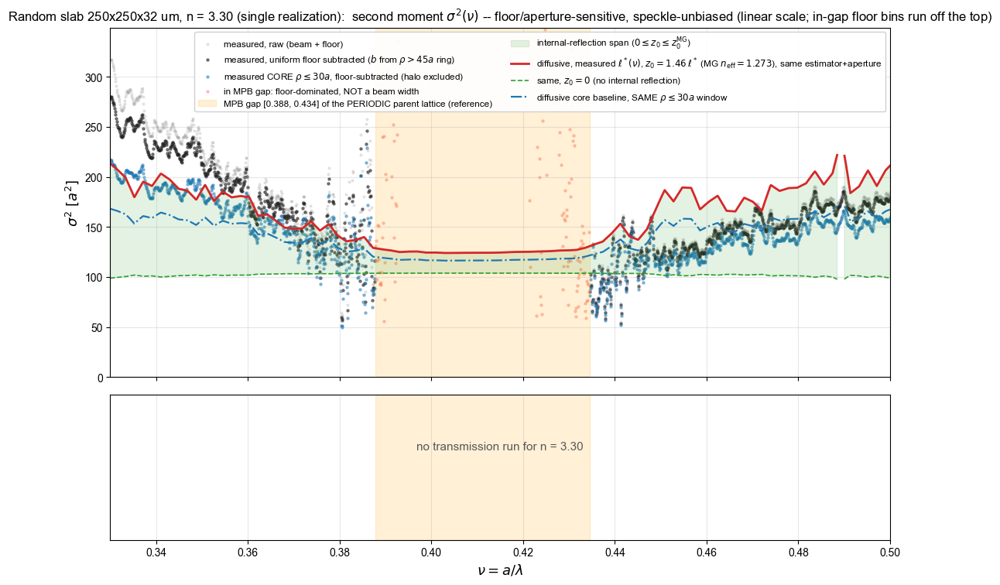

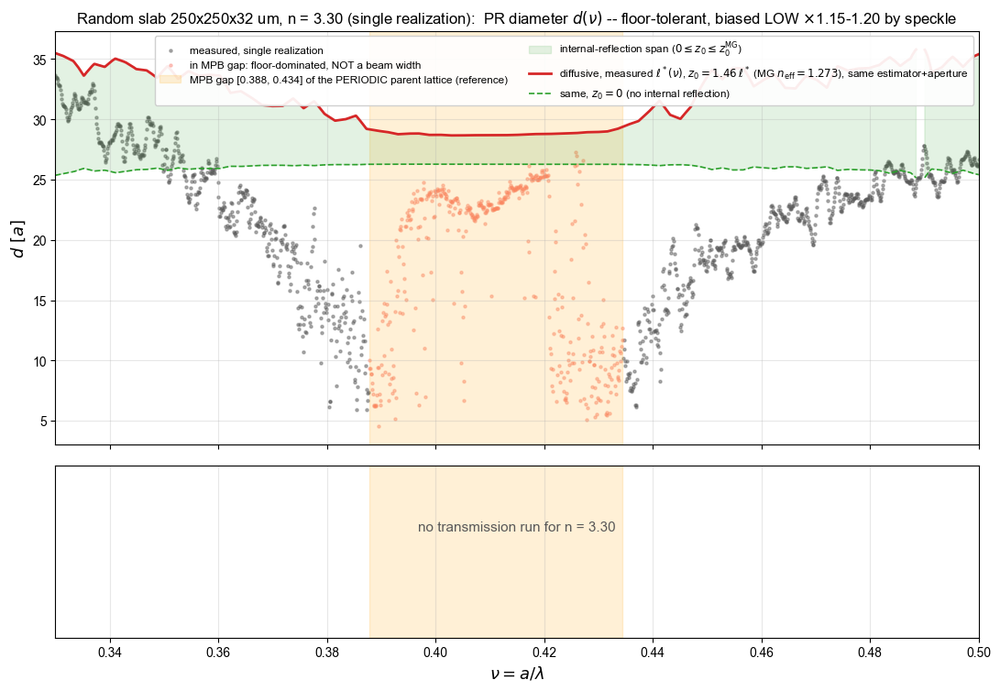

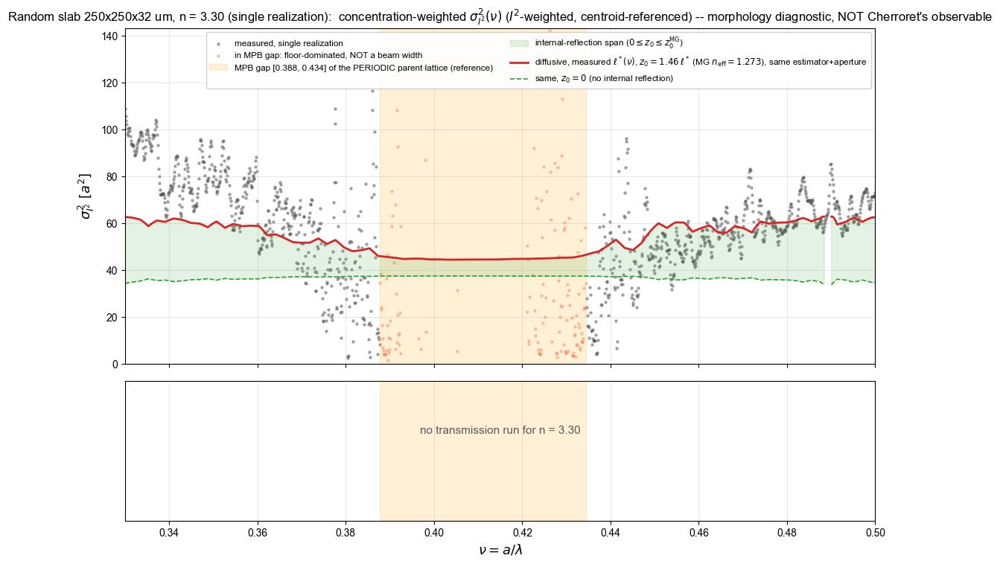

mid-band [0.460, 0.500], l* = 5.16 um:
  sigma^2 = 159 a^2 floor-subtracted (raw 163, speckle-unbiased)  vs diffusive 189 a^2 (z0=0: 101)   ratio 0.84
  core sigma^2 (rho<=30a) = 144 a^2  vs matched windowed baseline 158 a^2   ratio 0.91   <- halo-free, d-style comparison
  d       = 23.9 a raw -> ensemble 27.4-28.6 a  vs diffusive 34.2 a (z0=0: 25.8)   ratio 0.80-0.84
  sigma^2_I2 = 61 a^2  vs matched baseline 60 a^2   ratio 1.01   <- concentration-weighted, morphology only
GUARDRAIL: a CW width dip near a gap edge gives an attenuation/confinement length, NOT xi -- absorption and
  Bragg attenuation both give sigma^2 ~ 2 L L_att, and a single L cannot separate them.
sigma^2_I2 dips at the flanks like d because the bright quasi-mode spot dominates I^2 while most POWER
  stays diffusively spread (sigma^2 near-flat there) -- the sigma^2/d disagreement is itself the
  spot-on-background diagnostic.  The dip flags CONCENTRATION, not a mechanism: this structure mixes
  transport regimes (di

In [5]:
# --- Figures 1-3: sigma^2(nu), d(nu), sigma^2_I2(nu) vs diffusive baseline + T(nu) ---
def summary_figure(y, base, base0, ylab, title, logy, ylim=None, y2=None, y2lab="",
                   y3=None, base3=None, y3lab="", base3lab=""):
    fig, (ax, axb) = plt.subplots(2, 1, figsize=(13, 8.6), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1.25], "hspace": 0.07})
    if y2 is None:
        ax.scatter(nu[~INGAP], y[~INGAP], s=5, alpha=.45, color="0.35",
                   label="measured, single realization")
    else:                     # corrected series in front, raw behind for reference
        ax.scatter(nu[~INGAP], y[~INGAP], s=4, alpha=.18, color="0.55",
                   label="measured, raw (beam + floor)")
        mok = (~INGAP) & np.isfinite(y2)
        ax.scatter(nu[mok], y2[mok], s=5, alpha=.55, color="0.15", label=y2lab)
    if y3 is not None:        # windowed core series + its own matched baseline
        mok3 = (~INGAP) & np.isfinite(y3)
        ax.scatter(nu[mok3], y3[mok3], s=5, alpha=.45, color="tab:blue", label=y3lab)
    ax.scatter(nu[INGAP], y[INGAP], s=5, alpha=.40, color="salmon",
               label="in MPB gap: floor-dominated, NOT a beam width")
    ax.axvspan(*GAP, color="orange", alpha=.16,
               label=f"MPB gap [{GAP[0]:.3f}, {GAP[1]:.3f}] of the PERIODIC parent lattice (reference)")
    if base is not None:      # fully-diffusive prediction from the MEASURED l*(nu),
        # pushed through the SAME estimator, grid and aperture as the data
        b, b0 = np.where(DIFOK, base, np.nan), np.where(DIFOK, base0, np.nan)
        ax.fill_between(nu, b0, b, color="tab:green", alpha=.13,
                        label=r"internal-reflection span ($0\leq z_0\leq z_0^{\rm MG}$)")
        ax.plot(nu, b, "-", lw=2, color="tab:red",
                label=rf"diffusive, measured $\ell^*(\nu)$, $z_0={ZK:.2f}\,\ell^*$ (MG $n_{{\rm eff}}={NEFF:.3f}$), same estimator+aperture")
        ax.plot(nu, b0, "--", lw=1.2, color="tab:green",
                label=r"same, $z_0=0$ (no internal reflection)")
        if base3 is not None:
            ax.plot(nu, np.where(DIFOK, base3, np.nan), "-.", lw=1.6, color="tab:blue",
                    label=base3lab)
    if logy: ax.set_yscale("log")
    elif ylim is not None: ax.set_ylim(*ylim)   # linear: clip the floor-dominated in-gap bins
    ax.set_ylabel(ylab, fontsize=13); ax.set_title(title, fontsize=12)
    ax.legend(fontsize=8.5, loc="upper right", ncol=2, framealpha=.92)
    ax.grid(alpha=.3, which="both")
    # measured T(nu) on ITS OWN nu axis (supports differ -- never interpolated).
    if T_val is not None:
        axb.semilogy(T_nu, T_val, lw=.9, color="m", label=r"measured $T(\nu)$")
        axb.set_ylabel(r"$T(\nu)$", fontsize=11, color="m")
        axb.set_ylim(.4*T_val.min(), 3*T_val.max())
        axb.legend(fontsize=8, loc="lower right")
    else:
        axb.text(.5, .62, f"no transmission run for n = {n_index}", transform=axb.transAxes,
                 ha="center", fontsize=11, color="0.35")
        axb.set_yticks([])
    axb.axvspan(*GAP, color="orange", alpha=.16)
    axb.set_xlabel(r"$\nu = a/\lambda$", fontsize=13); axb.set_xlim(nu[0], nu[-1])
    axb.grid(alpha=.3, which="both")
    plt.show()

head = f"Random slab 250x250x32 um, n = {n_index} (single realization)"
_ymax = 1.1*np.nanmax(np.where(INGAP, np.nan, sig2))    # linear axis: out-of-gap data sets the scale
summary_figure(sig2, S2_DIF, S2_DIF0, r"$\sigma^2\ [a^2]$",
               head + r":  second moment $\sigma^2(\nu)$ -- floor/aperture-sensitive, speckle-unbiased"
                      " (linear scale; in-gap floor bins run off the top)",
               logy=False, ylim=(0, _ymax),
               y2=sig2_c, y2lab=r"measured, uniform floor subtracted ($b$ from $\rho>45a$ ring)",
               y3=sig2_w, base3=S2W_DIF,
               y3lab=rf"measured CORE $\rho\leq{RW/a:.0f}a$, floor-subtracted (halo excluded)",
               base3lab=rf"diffusive core baseline, SAME $\rho\leq{RW/a:.0f}a$ window")
summary_figure(d_nu, D_DIF, D_DIF0, r"$d\ [a]$",
               head + r":  PR diameter $d(\nu)$ -- floor-tolerant, biased LOW $\times$1.15-1.20 by speckle",
               logy=False)
_ymax2 = 1.1*np.nanmax(np.where(INGAP, np.nan, sigI2))
summary_figure(sigI2, SI2_DIF, SI2_DIF0, r"$\sigma^2_{I^2}\ [a^2]$",
               head + r":  concentration-weighted $\sigma^2_{I^2}(\nu)$ ($I^2$-weighted, centroid-referenced)"
                      r" -- morphology diagnostic, NOT Cherroret's observable",
               logy=False, ylim=(0, _ymax2))
if S2_DIF is not None:
    ok = MID & DIFOK
    ds, dsc, dd = np.median(sig2[ok]), np.nanmedian(sig2_c[ok]), np.median(d_nu[ok])
    bs, bd = np.median(S2_DIF[ok]), np.median(D_DIF[ok])
    dsw, bsw = np.nanmedian(sig2_w[ok]), np.median(S2W_DIF[ok])
    print(f"mid-band [{nu[ok][0]:.3f}, {nu[ok][-1]:.3f}], l* = {np.median(LSTAR[ok]):.2f} um:")
    print(f"  sigma^2 = {dsc:.0f} a^2 floor-subtracted (raw {ds:.0f}, speckle-unbiased)  "
          f"vs diffusive {bs:.0f} a^2 (z0=0: {np.median(S2_DIF0[ok]):.0f})   ratio {dsc/bs:.2f}")
    print(f"  core sigma^2 (rho<={RW/a:.0f}a) = {dsw:.0f} a^2  vs matched windowed baseline {bsw:.0f} a^2"
          f"   ratio {dsw/bsw:.2f}   <- halo-free, d-style comparison")
    print(f"  d       = {dd:.1f} a raw -> ensemble {1.15*dd:.1f}-{1.20*dd:.1f} a  vs diffusive {bd:.1f} a "
          f"(z0=0: {np.median(D_DIF0[ok]):.1f})   ratio {1.15*dd/bd:.2f}-{1.20*dd/bd:.2f}")
    dsi, bsi = np.median(sigI2[ok]), np.median(SI2_DIF[ok])
    print(f"  sigma^2_I2 = {dsi:.0f} a^2  vs matched baseline {bsi:.0f} a^2   ratio {dsi/bsi:.2f}"
          f"   <- concentration-weighted, morphology only")
print("GUARDRAIL: a CW width dip near a gap edge gives an attenuation/confinement length, NOT xi -- "
      "absorption and\n  Bragg attenuation both give sigma^2 ~ 2 L L_att, and a single L cannot separate them.")
print("sigma^2_I2 dips at the flanks like d because the bright quasi-mode spot dominates I^2 while most POWER\n"
      "  stays diffusively spread (sigma^2 near-flat there) -- the sigma^2/d disagreement is itself the\n"
      "  spot-on-background diagnostic.  The dip flags CONCENTRATION, not a mechanism: this structure mixes\n"
      "  transport regimes (diffusion, Bragg attenuation, quasi-mode transmission, incipient localization),\n"
      "  and Cherroret's ideal-diffusion/localization model maps onto none of the estimators one-to-one.")


decorrelation: HWHM = 4.2 bins = 4.5e-04 in nu  ->  window W = 60 bins (dnu_win = 6.4e-03, 26 windows), M_eff = 6.9  [3 s]


rows 495/498



core sigma^2 scatter about its matched baseline: per-bin 8.7 a^2 -> windowed 1.5 a^2  (sqrt(M_eff) = 2.6 expected)
mid-band medians (windows fully in [0.460, 0.500]):
  core sigma^2 = 143 +- 3 a^2 vs windowed baseline 157 a^2   ratio 0.91
  full sigma^2 = 156 a^2 vs baseline 188 a^2   ratio 0.83
  d(mean map) = 28.2 a -> contrast-corrected 29.1 a vs baseline 34.1 a   ratio 0.85
measured resolved contrast: C = 0.65 mid-band -> single-bin ensemble factor sqrt(1+C^2) = 1.19 (assumed 1.15-1.20); residual on the mean map: 1.031  [d pass 14 s]


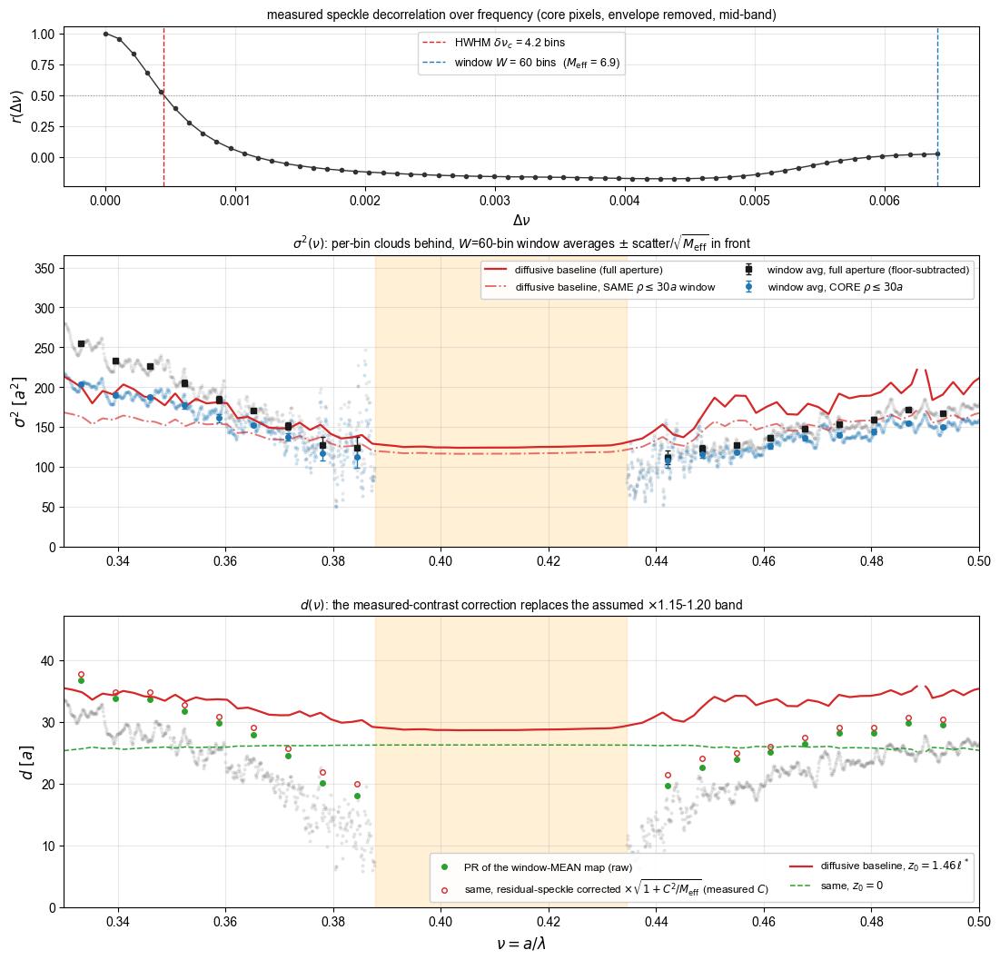

In [6]:
# --- speckle mitigation: measured nu-decorrelation + window-averaged estimators ---
# Adjacent nu bins carry partially independent speckle (Thouless dephasing across
# the path-length spread), so averaging over nu is a free surrogate ensemble --
# nothing is re-simulated.  Three steps, all data-driven:
#  (a) MEASURE the intensity decorrelation r(dnu) on bright-core pixels (per-pixel
#      envelope removed by a 101-bin running mean), take the HWHM dnu_c, and pick
#      the smallest window of W bins holding M_eff >= 8 quasi-independent patterns
#      (M_eff from the standard correlated-samples formula, positive-r part).
#      The negative dip and the recovery of r(k) toward lag ~60 are artifacts of
#      the 101-bin detrend filter, not physics -- W is capped at the lag range.
#  (b) sigma^2: ratio of window-SUMMED, floor-subtracted integrals over SIGOK bins
#      -- sigma^2 is speckle-unbiased bin by bin, so this is pure 1/sqrt(M_eff)
#      variance reduction (full aperture AND the rho<=RW core series); error bars
#      = within-window scatter / sqrt(M_eff).
#  (c) d: PR diameter of the window-MEAN intensity map.  int <I>^2 dA != <int I^2 dA>
#      -> one extra pass over the in-RAM fields.  The speckle bias shrinks
#      sqrt(1+C^2) -> sqrt(1+C^2/M_eff) with the resolved contrast C MEASURED per
#      bin from the same envelope-removed traces -- the assumed x1.15-1.20
#      ensemble factor becomes a data-driven correction (printed against it).
# CAVEATS: near the gap edges the true trend varies over ~ the window -> those
# windows mix trend into the average (they are shown, read them with that in
# mind); windows touching the gap or with >10% non-SIGOK bins are dropped; the
# low-nu halo is coherent spectral-edge leakage, NOT speckle -- it survives any
# averaging, so the core series stays the honest comparison there.
from scipy.ndimage import uniform_filter1d
t0 = time.time()
# (a) core-pixel traces -> envelope-free fluctuations F -> r(k), dnu_c, W, M_eff
PIXM = np.zeros((nx, ny), bool); PIXM[::2, ::2] = True
PIXM &= (Rg <= 20*a)                                   # envelope-lit core only
pix  = np.flatnonzero(PIXM.ravel())
Ipx  = ((np.abs(Ex_.reshape(nx*ny, N)[pix])*SC)**2
      + (np.abs(Ey_.reshape(nx*ny, N)[pix])*SC)**2
      + (np.abs(Ez_.reshape(nx*ny, N)[pix])*SC)**2)
env  = uniform_filter1d(Ipx, 101, axis=1, mode="nearest")
F    = Ipx/env - 1.0                                   # trend/envelope-free speckle
C2_bin = (F**2).mean(0)                                # resolved contrast^2 per bin
LAG  = np.arange(61)
JMa  = np.flatnonzero(MID)
JM   = JMa[:-LAG[-1]-1] if JMa.size > 3*LAG[-1] else np.arange(N - LAG[-1] - 1)[-400:]
r_k  = np.array([(F[:, JM]*F[:, JM + k]).mean() for k in LAG]); r_k /= r_k[0]
icx  = int(np.argmax(r_k < 0.5))                       # first crossing of 1/2
kc   = icx - 1 + (r_k[icx-1] - 0.5)/(r_k[icx-1] - r_k[icx]) if icx > 0 else LAG[-1]
dnb  = float(np.mean(np.diff(nu)))
rpos = np.clip(r_k, 0.0, None)                         # correlated-samples M_eff
def M_eff_of(W):
    k = np.arange(1, min(W, LAG[-1] + 1))
    return W/(1 + 2*np.sum((1 - k/W)*np.interp(k, LAG, rpos)))
Wc   = next((W for W in range(5, LAG[-1] + 1) if M_eff_of(W) >= 8.0), LAG[-1])
MEFF = M_eff_of(Wc)
NW, NB = N//Wc, (N//Wc)*Wc                             # full windows; ragged tail dropped
wid  = np.repeat(np.arange(NW), Wc)
def wsum(v, m=None):
    vv = np.where(m[:NB], v[:NB], 0.0) if m is not None else np.asarray(v)[:NB]
    return np.bincount(wid, vv, minlength=NW)
nu_W  = wsum(nu)/Wc
n_ok  = wsum(SIGOK.astype(float))
WOKF  = (n_ok/Wc >= 0.9) & (wsum(INGAP.astype(float)) == 0)
print(f"decorrelation: HWHM = {kc:.1f} bins = {kc*dnb:.1e} in nu  ->  window W = {Wc} bins "
      f"(dnu_win = {Wc*dnb:.1e}, {NW} windows), M_eff = {MEFF:.1f}  [{time.time()-t0:.0f} s]")
# (b) window-averaged sigma^2 (floor-subtracted; SIGOK bins only) + error bars
with np.errstate(invalid="ignore", divide="ignore"):   # in-gap windows: 0/0, masked by WOKF
    sig2_W  = np.where(WOKF, (wsum(M2  - b_nu*W2,  SIGOK)/wsum(S1  - b_nu*W0,  SIGOK))/a**2, np.nan)
    sig2w_W = np.where(WOKF, (wsum(M2w - b_nu*W2w, SIGOK)/wsum(S1w - b_nu*W0w, SIGOK))/a**2, np.nan)
s2b   = np.where(np.isfinite(sig2_w), sig2_w, 0.0)
mu1   = wsum(s2b, SIGOK)/np.maximum(n_ok, 1)
sd_W  = np.sqrt(np.clip(wsum(s2b**2, SIGOK)/np.maximum(n_ok, 1) - mu1**2, 0, None))
err_W = sd_W/np.sqrt(MEFF)                             # within-window scatter / sqrt(M_eff)
# (c) window-MEAN intensity maps -> speckle-reduced d + measured-contrast correction
t1 = time.time(); edges = np.arange(0, NB, Wc)
Iw = np.zeros((nx, ny, NW))
for i0 in range(0, nx, BL):
    i1 = min(i0 + BL, nx)
    I  = (np.abs(Ex_[i0:i1, :, 0, :NB]).astype(np.float64)*SC)**2
    I += (np.abs(Ey_[i0:i1, :, 0, :NB]).astype(np.float64)*SC)**2
    I += (np.abs(Ez_[i0:i1, :, 0, :NB]).astype(np.float64)*SC)**2
    Iw[i0:i1] = np.add.reduceat(I, edges, axis=2)
    del I; gc.collect(); print(f"rows {i1}/{nx}", end="\r")
Iw /= Wc
S1m = np.einsum("xyn,xy->n", Iw, AW); S2m = np.einsum("xyn,xy->n", Iw**2, AW)
d_W    = np.where(WOKF, d_of(S1m, S2m), np.nan)        # raw PR of the mean map
C2_W   = wsum(C2_bin)/Wc                               # measured resolved contrast^2
d_Wens = d_W*np.sqrt(1 + C2_W/MEFF)                    # residual-speckle correction
del Ipx, env, F, Iw; gc.collect()
# empirical noise reduction + updated mid-band comparison (matched baselines)
rstd  = lambda v: 1.4826*np.nanmedian(np.abs(v - np.nanmedian(v)))
MID_W = wsum(MID.astype(float)) == Wc
if S2_DIF is not None:
    BOKF    = wsum(DIFOK.astype(float)) == Wc
    S2W_D_W = np.where(BOKF, wsum(S2W_DIF)/Wc, np.nan)
    S2_D_W  = np.where(BOKF, wsum(S2_DIF)/Wc,  np.nan)
    D_D_W   = np.where(BOKF, wsum(D_DIF)/Wc,   np.nan)
    mb, mw = MID & DIFOK & np.isfinite(sig2_w), MID_W & BOKF & np.isfinite(sig2w_W)
    print(f"\ncore sigma^2 scatter about its matched baseline: per-bin {rstd(sig2_w[mb] - S2W_DIF[mb]):.1f} a^2 "
          f"-> windowed {rstd(sig2w_W[mw] - S2W_D_W[mw]):.1f} a^2  (sqrt(M_eff) = {np.sqrt(MEFF):.1f} expected)")
    print(f"mid-band medians (windows fully in [{nu[MID][0]:.3f}, {nu[MID][-1]:.3f}]):")
    print(f"  core sigma^2 = {np.nanmedian(sig2w_W[mw]):.0f} +- {np.nanmedian(err_W[mw]):.0f} a^2 "
          f"vs windowed baseline {np.nanmedian(S2W_D_W[mw]):.0f} a^2   "
          f"ratio {np.nanmedian(sig2w_W[mw])/np.nanmedian(S2W_D_W[mw]):.2f}")
    print(f"  full sigma^2 = {np.nanmedian(sig2_W[mw]):.0f} a^2 vs baseline {np.nanmedian(S2_D_W[mw]):.0f} a^2   "
          f"ratio {np.nanmedian(sig2_W[mw])/np.nanmedian(S2_D_W[mw]):.2f}")
    print(f"  d(mean map) = {np.nanmedian(d_W[mw]):.1f} a -> contrast-corrected {np.nanmedian(d_Wens[mw]):.1f} a "
          f"vs baseline {np.nanmedian(D_D_W[mw]):.1f} a   ratio {np.nanmedian(d_Wens[mw])/np.nanmedian(D_D_W[mw]):.2f}")
else:
    S2W_D_W = S2_D_W = D_D_W = None
print(f"measured resolved contrast: C = {np.sqrt(np.median(C2_bin[MID])):.2f} mid-band -> single-bin ensemble "
      f"factor sqrt(1+C^2) = {np.sqrt(1 + np.median(C2_bin[MID])):.2f} (assumed 1.15-1.20); residual on the "
      f"mean map: {np.nanmedian(np.sqrt(1 + C2_W[MID_W]/MEFF)):.3f}  [d pass {time.time()-t1:.0f} s]")
# figure: r(dnu) + both estimators, per-bin clouds behind, window averages in front
fig, (axr, axs, axd) = plt.subplots(3, 1, figsize=(13, 12.6),
    gridspec_kw={"height_ratios": [1.1, 2, 2], "hspace": 0.28})
axr.plot(LAG*dnb, r_k, "o-", ms=3, lw=1, color="0.2")
axr.axhline(0.5, color="0.6", lw=.8, ls=":")
axr.axvline(kc*dnb, color="tab:red", lw=1, ls="--", label=rf"HWHM $\delta\nu_c$ = {kc:.1f} bins")
axr.axvline(Wc*dnb, color="tab:blue", lw=1, ls="--",
            label=rf"window $W$ = {Wc} bins  ($M_{{\rm eff}}$ = {MEFF:.1f})")
axr.set_xlabel(r"$\Delta\nu$", fontsize=11); axr.set_ylabel(r"$r(\Delta\nu)$", fontsize=11)
axr.set_title("measured speckle decorrelation over frequency (core pixels, envelope removed, mid-band)",
              fontsize=10)
axr.grid(alpha=.3); axr.legend(fontsize=9)
for ax, ylab in ((axs, r"$\sigma^2\ [a^2]$"), (axd, r"$d\ [a]$")):
    ax.axvspan(*GAP, color="orange", alpha=.16)
    ax.set_xlim(nu[0], nu[-1]); ax.grid(alpha=.3); ax.set_ylabel(ylab, fontsize=12)
mok = (~INGAP) & np.isfinite(sig2_w)
axs.scatter(nu[mok], sig2_w[mok], s=4, alpha=.15, color="tab:blue")
mok = (~INGAP) & np.isfinite(sig2_c)
axs.scatter(nu[mok], sig2_c[mok], s=4, alpha=.12, color="0.5")
axs.errorbar(nu_W, sig2_W, yerr=err_W, fmt="s", ms=4, lw=0, elinewidth=1, capsize=2,
             color="0.1", label=r"window avg, full aperture (floor-subtracted)")
axs.errorbar(nu_W, sig2w_W, yerr=err_W, fmt="o", ms=4, lw=0, elinewidth=1, capsize=2,
             color="tab:blue", label=rf"window avg, CORE $\rho\leq{RW/a:.0f}a$")
if S2_DIF is not None:
    axs.plot(nu, np.where(DIFOK, S2_DIF, np.nan), "-", lw=1.6, color="tab:red",
             label="diffusive baseline (full aperture)")
    axs.plot(nu, np.where(DIFOK, S2W_DIF, np.nan), "-.", lw=1.4, color="tab:red", alpha=.65,
             label=rf"diffusive baseline, SAME $\rho\leq{RW/a:.0f}a$ window")
axs.set_ylim(0, 1.15*np.nanmax(np.where(INGAP, np.nan, sig2)))
axs.set_title(rf"$\sigma^2(\nu)$: per-bin clouds behind, $W$={Wc}-bin window averages "
              rf"$\pm$ scatter/$\sqrt{{M_{{\rm eff}}}}$ in front", fontsize=10)
axs.legend(fontsize=8.5, loc="upper right", ncol=2, framealpha=.92)
axd.scatter(nu[~INGAP], d_nu[~INGAP], s=4, alpha=.15, color="0.5")
axd.plot(nu_W, d_W, "o", ms=4, color="tab:green", label="PR of the window-MEAN map (raw)")
axd.plot(nu_W, d_Wens, "o", ms=4, color="tab:red", mfc="none",
         label=r"same, residual-speckle corrected $\times\sqrt{1+C^2/M_{\rm eff}}$ (measured $C$)")
if D_DIF is not None:
    axd.plot(nu, np.where(DIFOK, D_DIF, np.nan), "-", lw=1.6, color="tab:red",
             label=rf"diffusive baseline, $z_0={ZK:.2f}\,\ell^*$")
    axd.plot(nu, np.where(DIFOK, D_DIF0, np.nan), "--", lw=1.1, color="tab:green",
             label=r"same, $z_0=0$")
axd.set_ylim(0, 1.25*np.nanmax(d_Wens))
axd.set_xlabel(r"$\nu = a/\lambda$", fontsize=12)
axd.set_title(r"$d(\nu)$: the measured-contrast correction replaces the assumed $\times$1.15-1.20 band",
              fontsize=10)
axd.legend(fontsize=8.5, loc="lower right", ncol=2, framealpha=.92)
plt.show()

rows 495/498



6/7 windows kernel-fit OK (log-rms <= 0.15); median rms 0.068  [25 s]
z0_eff/l*_Born: below gap 2.15, mid-band 0.90  (plotted MG/ZPW input: 1.46);  l*_eff at the MG ratio below gap = 7.2 um vs Born 4.9 um
  below gap: measured/CALIBRATED  sigma^2 1.04,  d 0.92,  sigma^2_I2 1.14   (vs plotted MG baseline: 1.28 / 1.00 / 1.31)
  mid-band : measured/CALIBRATED  sigma^2 1.01,  d 0.90,  sigma^2_I2 1.12   (vs plotted MG baseline: 0.87 / 0.84 / 0.99)


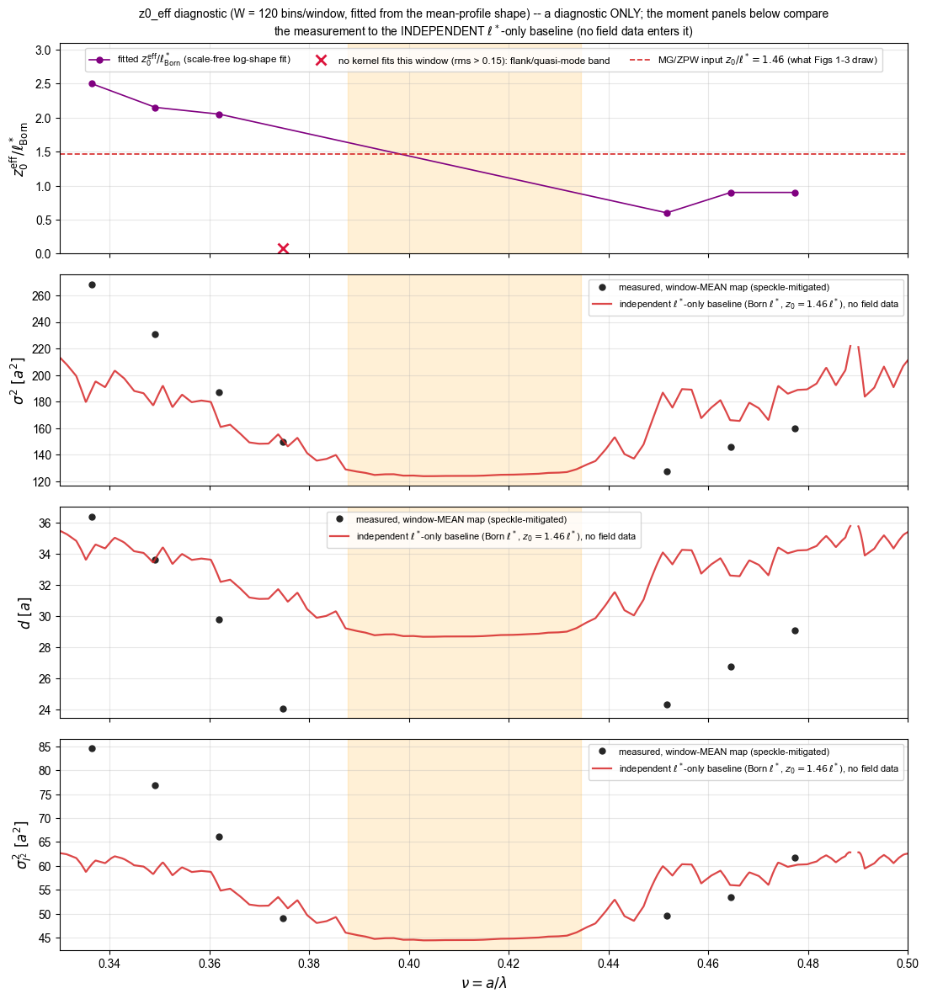

NOTE: the z0_eff-calibrated values are field-data-derived, so they are PRINTED as consistency
  ratios only and never drawn as a baseline (2026-08-28).  The drawn baseline is l*-only.  The
  physics content of the fit is (i) the z0_eff(nu) trend = the size of the Born-g input error
  (l* too small at long wavelengths), and (ii) the flank windows where NO extrapolated-boundary
  kernel fits at all -- quasi-mode/attenuation dominated, no diffusive width applies.


In [7]:
# --- profile-calibrated baseline: z0_eff(nu) fitted from nu-window mean profiles ---
# WHY (2026-08-27): below nu ~ 0.36 all three estimators sit ABOVE the plotted
# baseline by mutually consistent factors, yet the nu-averaged exit profile there
# is STILL a single extrapolated-boundary kernel -- with z0_eff ~ 2.4 l*_Born
# instead of the MG/ZPW 1.46 l* (mid-band: ~0.95 l*).  The Born/RDG g (generator
# warns |m-1| >> 0.1 at n_rod = 3.3) misestimates the nu-TREND of l*: too small on
# the long-wavelength side (Rayleigh regime), slightly too large mid-band.  So
# invert the logic: fit z0 per nu window from the measured mean-profile SHAPE
# (l* held at the Born value; the log fit is scale-free and the tail pins L+2z0;
# z0_eff is an EFFECTIVE parameter absorbing every input error -- Born l*, MG
# n_eff, ZPW R), then push (l*_Born, z0_eff) through dif_pair.  Below-gap
# agreement then follows BY CONSTRUCTION wherever the kernel fits (log-rms
# printed; mid-band reference ~0.05, rms > 0.15 = kernel does NOT describe that
# band); the informative residuals are the gap flanks, where no kernel fits.
if LSTAR is None:
    print(f"!! no external ls/g files for n = {n_index} -> no profile calibration.")
else:
    t0 = time.time(); WFIT = 120; NWF = N//WFIT
    nuF = nu[:NWF*WFIT].reshape(NWF, WFIT).mean(1)
    LTF = np.median(LSTAR[:NWF*WFIT].reshape(NWF, WFIT), axis=1)
    OKF = (~INGAP[:NWF*WFIT].reshape(NWF, WFIT).any(1)
           & (DIFOK[:NWF*WFIT].reshape(NWF, WFIT).mean(1) >= 0.9))
    IwF = np.zeros((nx, ny, NWF))                # window-MEAN maps (cell-06 deletes its own)
    for i0 in range(0, nx, BL):
        i1 = min(i0+BL, nx)
        I  = (np.abs(Ex_[i0:i1, :, 0, :NWF*WFIT]).astype(np.float64)*SC)**2
        I += (np.abs(Ey_[i0:i1, :, 0, :NWF*WFIT]).astype(np.float64)*SC)**2
        I += (np.abs(Ez_[i0:i1, :, 0, :NWF*WFIT]).astype(np.float64)*SC)**2
        IwF[i0:i1] = np.add.reduceat(I, np.arange(0, NWF*WFIT, WFIT), axis=2)/WFIT
        del I; gc.collect(); print(f"rows {i1}/{nx}", end="\r")
    RB  = np.arange(0, 49)*a; rcF = 0.5*(RB[:-1] + RB[1:])   # azimuthal annuli, true grid
    IDX = np.digitize(Rg.ravel(), RB)
    AB  = np.bincount(IDX, weights=AW.ravel(), minlength=RB.size + 1)[1:RB.size]
    MF  = (rcF >= 3*a) & (rcF <= 46*a)
    Z0F = np.full(NWF, np.nan); RMSF = np.full(NWF, np.nan)
    for i in np.flatnonzero(OKF):                # scale-free log-shape fit of z0
        pr = np.bincount(IDX, weights=(IwF[..., i]*AW).ravel(),
                         minlength=RB.size + 1)[1:RB.size]/AB
        best = (np.inf, np.nan)
        for zk in np.linspace(0.05, 3.0, 60):
            res = np.log(pr[MF]/T_rho(LTF[i], zk*LTF[i], rcF[MF])); res -= res.mean()
            if (r2 := (res**2).mean()) < best[0]: best = (r2, zk)
        RMSF[i], Z0F[i] = np.sqrt(best[0]), best[1]*LTF[i]
    FITOK = OKF & (RMSF <= 0.15)                 # kernel actually describes the window
    CAL = np.full((NWF, 5), np.nan)              # calibrated (d, s2, -, s2w, s2_I2)
    for i in np.flatnonzero(FITOK): CAL[i] = dif_pair(LTF[i], Z0F[i])
    # measured estimator triple of the SAME mean maps (speckle-mitigated by the window)
    S1m = np.einsum("xyn,xy->n", IwF, AW);       S2m = np.einsum("xyn,xy->n", IwF**2, AW)
    M2m = np.einsum("xyn,xy->n", IwF, Rg2*AW);   Q2m = np.einsum("xyn,xy->n", IwF**2, Rg2*AW)
    Qxm = np.einsum("xyn,xy->n", IwF**2, Xg*AW); Qym = np.einsum("xyn,xy->n", IwF**2, Yg*AW)
    sig2F, dF, sigI2F = sig2_of(S1m, M2m), d_of(S1m, S2m), sigI2_of(S2m, Qxm, Qym, Q2m)
    del IwF; gc.collect()
    BG = FITOK & (nuF < GAP[0]); MB = FITOK & (nuF >= 0.46)
    print(f"\n{FITOK.sum()}/{OKF.sum()} windows kernel-fit OK (log-rms <= 0.15); "
          f"median rms {np.nanmedian(RMSF[FITOK]):.3f}  [{time.time()-t0:.0f} s]")
    print(f"z0_eff/l*_Born: below gap {np.nanmedian((Z0F/LTF)[BG]):.2f}, "
          f"mid-band {np.nanmedian((Z0F/LTF)[MB]):.2f}  (plotted MG/ZPW input: {ZK:.2f});  "
          f"l*_eff at the MG ratio below gap = {np.nanmedian(Z0F[BG])/ZK:.1f} um "
          f"vs Born {np.nanmedian(LTF[BG]):.1f} um")
    for m, tag in ((BG, "below gap"), (MB, "mid-band ")):
        print(f"  {tag}: measured/CALIBRATED  sigma^2 {np.nanmedian((sig2F/CAL[:, 1])[m]):.2f},  "
              f"d {np.nanmedian((dF/CAL[:, 0])[m]):.2f},  sigma^2_I2 {np.nanmedian((sigI2F/CAL[:, 4])[m]):.2f}"
              f"   (vs plotted MG baseline: {np.nanmedian((sig2F/np.interp(nuF, nu, S2_DIF))[m]):.2f} / "
              f"{np.nanmedian((dF/np.interp(nuF, nu, D_DIF))[m]):.2f} / "
              f"{np.nanmedian((sigI2F/np.interp(nuF, nu, SI2_DIF))[m]):.2f})")
    fig, (axz, axs_, axd_, axi_) = plt.subplots(4, 1, figsize=(13, 14), sharex=True,
                                                gridspec_kw={"hspace": 0.10})
    axz.plot(nuF[FITOK], (Z0F/LTF)[FITOK], "o-", color="purple", lw=1.2, ms=5,
             label=r"fitted $z_0^{\rm eff}/\ell^*_{\rm Born}$ (scale-free log-shape fit)")
    bad = OKF & ~FITOK
    if bad.any():
        axz.plot(nuF[bad], np.full(bad.sum(), 0.08), "x", color="crimson", ms=8, mew=2,
                 label="no kernel fits this window (rms > 0.15): flank/quasi-mode band")
    axz.axhline(ZK, color="tab:red", lw=1.2, ls="--",
                label=rf"MG/ZPW input $z_0/\ell^* = {ZK:.2f}$ (what Figs 1-3 draw)")
    axz.set_ylabel(r"$z_0^{\rm eff}/\ell^*_{\rm Born}$", fontsize=12); axz.set_ylim(0, 3.1)
    axz.legend(fontsize=8.5, loc="upper center", ncol=3)
    axz.set_title(f"z0_eff diagnostic (W = {WFIT} bins/window, fitted from the mean-profile shape) -- a "
                  "diagnostic ONLY; the moment panels below compare\nthe measurement to the INDEPENDENT "
                  r"$\ell^*$-only baseline (no field data enters it)", fontsize=10)
    # moment panels draw ONLY the independent l*-only baseline (2026-08-28, user
    # decision): the z0_eff-calibrated values are field-data-derived, so they stay
    # PRINTED as consistency ratios above but are never drawn as a "baseline".
    for ax, y, ref, lab in ((axs_, sig2F,  S2_DIF,  r"$\sigma^2\ [a^2]$"),
                            (axd_, dF,     D_DIF,   r"$d\ [a]$"),
                            (axi_, sigI2F, SI2_DIF, r"$\sigma^2_{I^2}\ [a^2]$")):
        ax.plot(nuF[OKF], y[OKF], "o", ms=5, color="0.15",
                label="measured, window-MEAN map (speckle-mitigated)")
        ax.plot(nu, np.where(DIFOK, ref, np.nan), "-", lw=1.6, color="tab:red", alpha=.85,
                label=rf"independent $\ell^*$-only baseline (Born $\ell^*$, $z_0 = {ZK:.2f}\,\ell^*$), no field data")
        ax.set_ylabel(lab, fontsize=12); ax.legend(fontsize=8, loc="best")
    for ax in (axz, axs_, axd_, axi_):
        ax.axvspan(*GAP, color="orange", alpha=.16); ax.grid(alpha=.3)
    axi_.set_xlabel(r"$\nu = a/\lambda$", fontsize=12); axi_.set_xlim(nu[0], nu[-1])
    plt.show()
    print("NOTE: the z0_eff-calibrated values are field-data-derived, so they are PRINTED as consistency\n"
          "  ratios only and never drawn as a baseline (2026-08-28).  The drawn baseline is l*-only.  The\n"
          "  physics content of the fit is (i) the z0_eff(nu) trend = the size of the Born-g input error\n"
          "  (l* too small at long wavelengths), and (ii) the flank windows where NO extrapolated-boundary\n"
          "  kernel fits at all -- quasi-mode/attenuation dominated, no diffusive width applies.")


max pass rows 495/498



floor/peak: median b/I_max = 1.5e-05 out of gap -> f = 1e-6 cuts nothing  [46 s]
mid-band medians vs matched baseline (MG z0):
  f = 1e-06:  sigma^2_th =  165 a^2,  d_th = 24.0 a, baseline  189/34.2   (raw: 165 / 24.0)
  f = 1e-03:  sigma^2_th =  140 a^2,  d_th = 23.4 a, baseline  182/34.1   (raw: 165 / 24.0)
  f = 1e-02:  sigma^2_th =   98 a^2,  d_th = 20.0 a, baseline  155/33.2   (raw: 165 / 24.0)
  f = 5e-02:  sigma^2_th =   60 a^2,  d_th = 12.1 a, baseline  113/30.3   (raw: 165 / 24.0)


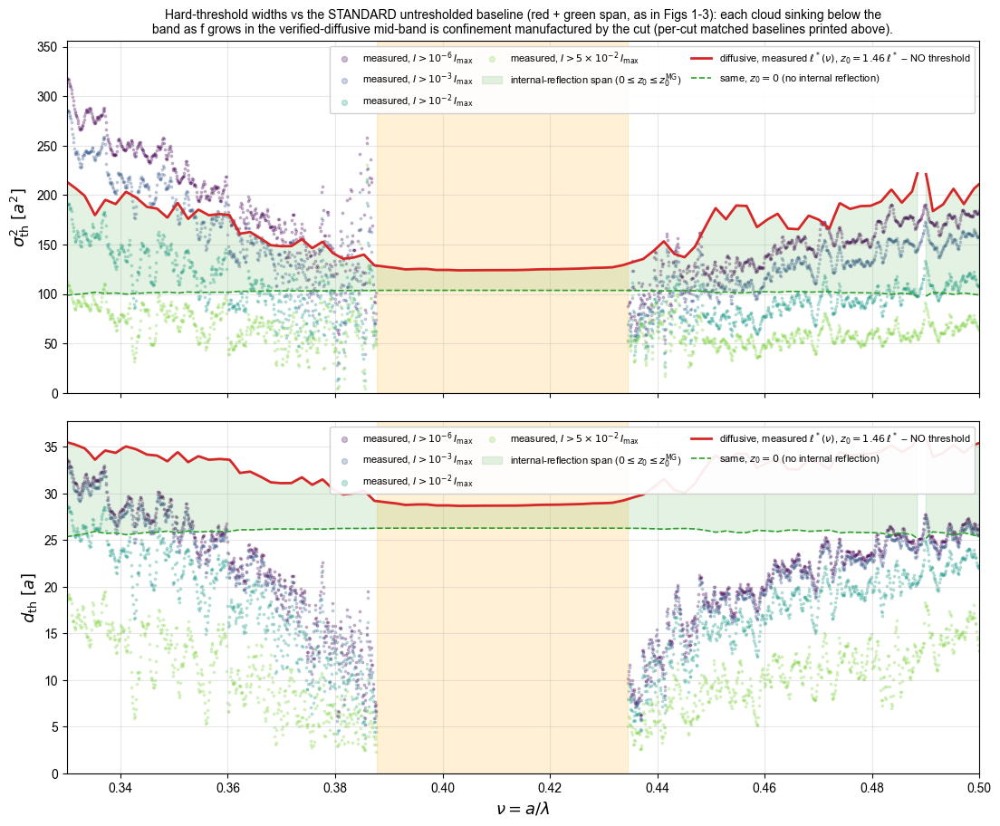

READING: f = 1e-6 == raw (control).  By f = 1e-2 the verified-diffusive mid-band already reads ~40%
  'narrower' than its own matched baseline -- confinement manufactured by the cut, not transport.
  The legitimate versions of this idea stay the estimators of record: measured-floor subtraction
  (exact, no free parameter), the rho <= 30a windowed sigma^2 (cut cancels against the baseline),
  and sigma^2_I2 (soft, parameter-free intensity weighting).


In [8]:
# --- hard-threshold widths: sigma^2_th(nu) and d_th(nu) for I > f x I_max(bin) ---
# Requested experiment (2026-08-28): discard pixels below a floor f x the per-bin
# peak, recompute both widths.  Audit verdict that motivated this cell (README):
# the hard cut FAKES confinement -- it trims the exponential tails that carry
# sigma^2 even where transport is verified diffusive (mid-band, f = 1e-2: -40%),
# the result never plateaus in f (no "right" threshold exists), and the per-bin
# max is a speckle grain ~2.7x the envelope peak, so the effective cut wanders
# bin to bin.  This cell makes that visible rather than hiding it: every f gets
# its own MATCHED baseline (the same cut applied to the MG-z0 kernel), so the gap
# between a cloud and the line of ITS OWN color is pure estimator bias, and the
# spread BETWEEN colors is the arbitrariness of f.  f = 1e-6 is the control: the
# measured uniform floor sits well above 1e-6 x max outside the gap, so that cut
# removes nothing and reproduces the raw estimators (asserted below).
THF = (1e-6, 1e-3, 1e-2, 5e-2)
t0 = time.time()
IMAXB = np.zeros(N)                              # pass A: per-bin peak intensity
for i0 in range(0, nx, BL):
    i1 = min(i0+BL, nx)
    I  = (np.abs(Ex_[i0:i1, :, 0, :]).astype(np.float64)*SC)**2
    I += (np.abs(Ey_[i0:i1, :, 0, :]).astype(np.float64)*SC)**2
    I += (np.abs(Ez_[i0:i1, :, 0, :]).astype(np.float64)*SC)**2
    IMAXB = np.maximum(IMAXB, I.max(axis=(0, 1)))
    del I; gc.collect(); print(f"max pass rows {i1}/{nx}", end="\r")
S1T = np.zeros((len(THF), N)); S2T = np.zeros((len(THF), N)); M2T = np.zeros((len(THF), N))
for i0 in range(0, nx, BL):                      # pass B: thresholded sums
    i1 = min(i0+BL, nx)
    I  = (np.abs(Ex_[i0:i1, :, 0, :]).astype(np.float64)*SC)**2
    I += (np.abs(Ey_[i0:i1, :, 0, :]).astype(np.float64)*SC)**2
    I += (np.abs(Ez_[i0:i1, :, 0, :]).astype(np.float64)*SC)**2
    P  = I.reshape(-1, N)
    Wp = (wxS[i0:i1, None]*wyS[None, :]).ravel()
    R2p = Rg2[i0:i1].ravel()
    for j, fth in enumerate(THF):
        PW = np.where(P > fth*IMAXB, P, 0.0)
        S1T[j] += np.einsum("pn,p->n", PW,   Wp)
        S2T[j] += np.einsum("pn,p->n", PW*P, Wp)     # I^2 on the kept pixels
        M2T[j] += np.einsum("pn,p->n", PW,   R2p*Wp)
        del PW
    del I, P; gc.collect(); print(f"threshold pass rows {i1}/{nx}", end="\r")
sig2T, dT = (M2T/S1T)/a**2, 2*np.sqrt((S1T**2/S2T)/np.pi)/a
assert np.median(np.abs(sig2T[0] - sig2)/sig2) < 5e-3, "f=1e-6 must reproduce the raw sigma^2"
# matched thresholded baselines: same cut on the MG-z0 kernel (Figs 1-3 convention)
if LSTAR is not None:
    knT = np.geomspace(LSTAR.min(), LSTAR.max(), 12)
    BT  = np.zeros((len(THF), 2, knT.size))
    for k, lt in enumerate(knT):
        z0 = ZK*lt
        r  = np.linspace(0.0, 6*(L_slab + 2*z0), 1200)
        Tr = np.clip(T_rho(lt, z0, r), 0, None)
        Ik = np.interp(Rg.ravel(), r, Tr, right=0.0).reshape(Rg.shape)
        mx = Ik.max()
        for j, fth in enumerate(THF):
            m = Ik > fth*mx
            s1, s2, m2 = (Ik*AW)[m].sum(), (Ik**2*AW)[m].sum(), (Rg2*Ik*AW)[m].sum()
            BT[j, 0, k], BT[j, 1, k] = d_of(s1, s2), sig2_of(s1, m2)
    D_T  = np.stack([np.interp(LSTAR, knT, BT[j, 0]) for j in range(len(THF))])
    S2_T = np.stack([np.interp(LSTAR, knT, BT[j, 1]) for j in range(len(THF))])
else:
    D_T = S2_T = None
print(f"\nfloor/peak: median b/I_max = {np.median(b_nu/IMAXB):.1e} out of gap -> f = 1e-6 cuts nothing "
      f" [{time.time()-t0:.0f} s]")
print("mid-band medians vs matched baseline (MG z0):")
for j, fth in enumerate(THF):
    bs = f", baseline {np.median(S2_T[j][MID]):4.0f}/{np.median(D_T[j][MID]):4.1f}" if S2_T is not None else ""
    print(f"  f = {fth:.0e}:  sigma^2_th = {np.median(sig2T[j][MID]):4.0f} a^2,  "
          f"d_th = {np.median(dT[j][MID]):4.1f} a{bs}   "
          f"(raw: {np.median(sig2[MID]):.0f} / {np.median(d_nu[MID]):.1f})")
CTH = plt.cm.viridis(np.linspace(0.0, 0.82, len(THF)))
fig, (axs_, axd_) = plt.subplots(2, 1, figsize=(13, 10.5), sharex=True,
                                 gridspec_kw={"hspace": 0.08})
# figure baseline = the STANDARD untresholded presentation of Figs 1-3 (red MG-z0
# curve + green z0 = 0 span), per user request; the per-cut MATCHED baselines stay
# PRINTED above -- the mid-band gap between each cloud and the printed matched
# value is the manufactured-confinement bias.
for ax, Yv, ref, ref0, lab in ((axs_, sig2T, S2_DIF, S2_DIF0, r"$\sigma^2_{\rm th}\ [a^2]$"),
                               (axd_, dT,    D_DIF,  D_DIF0,  r"$d_{\rm th}\ [a]$")):
    for j, fth in enumerate(THF):
        exj = int(np.floor(np.log10(fth))); mj = fth/10**exj
        labj = (rf"$I > 10^{{{exj}}}\,I_{{\max}}$" if mj == 1 else
                rf"$I > {mj:g}\times10^{{{exj}}}\,I_{{\max}}$")
        ax.scatter(nu[~INGAP], Yv[j][~INGAP], s=3, alpha=.25, color=CTH[j],
                   label="measured, " + labj)
    if ref is not None:
        b, b0 = np.where(DIFOK, ref, np.nan), np.where(DIFOK, ref0, np.nan)
        ax.fill_between(nu, b0, b, color="tab:green", alpha=.13,
                        label=r"internal-reflection span ($0\leq z_0\leq z_0^{\rm MG}$)")
        ax.plot(nu, b, "-", lw=2, color="tab:red",
                label=rf"diffusive, measured $\ell^*(\nu)$, $z_0={ZK:.2f}\,\ell^*$ -- NO threshold")
        ax.plot(nu, b0, "--", lw=1.2, color="tab:green",
                label=r"same, $z_0=0$ (no internal reflection)")
    ax.axvspan(*GAP, color="orange", alpha=.16)
    ax.set_ylabel(lab, fontsize=13); ax.grid(alpha=.3)
    ax.set_ylim(0, 1.12*np.nanmax(np.where(INGAP, np.nan, Yv[0])))
    ax.legend(fontsize=8, loc="upper right", ncol=3, columnspacing=0.9,
              markerscale=2.5, framealpha=.92)
axs_.set_title("Hard-threshold widths vs the STANDARD untresholded baseline (red + green span, as in Figs 1-3): "
               "each cloud sinking below the\nband as f grows in the verified-diffusive mid-band is confinement "
               "manufactured by the cut (per-cut matched baselines printed above).", fontsize=10)
axd_.set_xlabel(r"$\nu = a/\lambda$", fontsize=13); axd_.set_xlim(nu[0], nu[-1])
plt.show()
print("READING: f = 1e-6 == raw (control).  By f = 1e-2 the verified-diffusive mid-band already reads ~40%\n"
      "  'narrower' than its own matched baseline -- confinement manufactured by the cut, not transport.\n"
      "  The legitimate versions of this idea stay the estimators of record: measured-floor subtraction\n"
      "  (exact, no free parameter), the rho <= 30a windowed sigma^2 (cut cancels against the baseline),\n"
      "  and sigma^2_I2 (soft, parameter-free intensity weighting).")


l* knot 10/10
[130 s]  strong-attenuation check: sigma^2(LA=0.4 um) table 3 vs 2(L-l*)L_att = 3 a^2 (window-truncated below)
  lower edge  nu = [0.3817, 0.3867]  (47 bins):  L_att^d = 1.2-1.3 a, L_att^s2 = inf a;  100% of bins below the z0=0 diffusive bound
  upper edge  nu = [0.4355, 0.4405]  (47 bins):  L_att^d = 1.0-1.0 a, L_att^s2 = 4.9 a;  100% of bins below the z0=0 diffusive bound


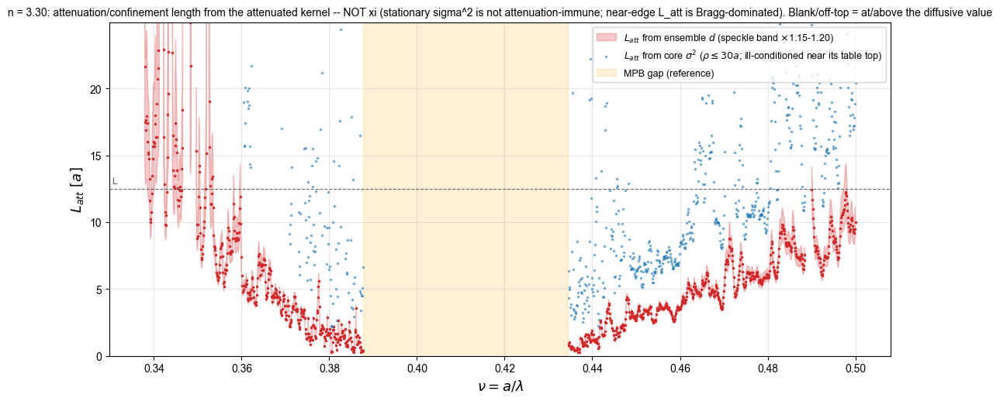

GUARDRAIL (reaffirmed by the 2026-08-25 audit): CW L_att is an attenuation/confinement scale -- localization, Bragg
  evanescence and absorption are NOT separable from one stationary profile. xi needs the time domain + L-scaling;
  the TD plateaus (105-147 a^2 = 0.67-0.94 L^2) sit at the mobility-edge asymptote -> extent ~ L, critical/marginal.


In [9]:
# --- L_att(nu) from the exit profile: attenuated-kernel inversion ----------------
# Transverse confinement/attenuation enters the slab kernel through
# kappa = sqrt(q^2 + L_att^-2):
#     T(q) = sinh(kappa(l*+z0)) cosh(kappa z0)/sinh(kappa(L+2z0))
# L_att -> inf recovers the diffusive kernel; L_att << L gives the Gaussian limit
# sigma^2 -> 2(L-l*)L_att (asserted below).  d and the core sigma^2_w of this
# kernel go through the SAME estimators/grid/window as the data and are monotonic
# in L_att -> invert per frequency bin.
# WHAT THIS IS -- AND IS NOT (adversarial audit 2026-08-25): stationary sigma^2,
# unlike pulsed sigma^2(t), is NOT attenuation-immune, so the fitted 1/L_att^2
# lumps localization, Bragg evanescence and absorption with no way to apportion
# them from one CW profile; near a gap edge the Bragg term generically dominates.
# L_att(nu) is therefore an ATTENUATION/CONFINEMENT length, not xi (the old
# guardrail stands).  Its value here is the monochromatic nu-resolution of the
# confinement onset (the funnel into both edges) and the d-route spot-core scale.
# Audit notes: the d-route (~1.0-1.3a at the edges) is numerically solid (inside
# the invertible range, insensitive to the speckle band); the sigma^2-route sits
# just below the ill-conditioned flat top of its table (window-sensitive there;
# its earlier "4.9a = time-domain match" was retracted -- the TD plateaus
# 105-147 a^2 fed through this table give 8.6a..inf).  "inf" bins mean the core
# sigma^2 is at/above the windowed diffusive value: EITHER diffusion-consistent
# OR halo-contaminated (the below-gap Born-g/floor excess) -- a mixed population,
# not a positive statement.  Speckle band 1.15-1.20 is invalid at few-mode bins
# (systematic only).  The TD plateaus themselves sit at 0.67-0.94 L^2, i.e. the
# mobility-edge asymptote sigma_inf ~ L: extent ~ L, critical/marginal -- xi
# needs L-scaling, not this panel.
if S2_DIF is not None:
    t0 = time.time()
    LA  = np.geomspace(0.4, 400.0, 25)               # candidate L_att [um]
    LK2 = np.geomspace(LSTAR.min(), LSTAR.max(), 10) # l* knots
    def T_rho_att(lt, z0, alpha, r, nq=4000):
        Cc, A, B = L_slab + 2*z0, lt + z0, z0
        q = np.linspace(1e-12, min(80.0/(Cc - A - B), 700.0/Cc), nq)
        kap = np.sqrt(q*q + alpha*alpha)
        Tq = np.sinh(kap*A)*np.cosh(kap*B)/np.sinh(kap*Cc)
        out = np.empty(r.size)
        for s0 in range(0, r.size, 512):
            sl = slice(s0, s0 + 512)
            out[sl] = simpson(j0(np.outer(r[sl], q))*(Tq*q), x=q, axis=1)/(2*np.pi)
        return out
    def d_att(lt, alpha):
        z0 = ZK*lt
        r  = np.linspace(0.0, 6*(L_slab + 2*z0), 1200)
        Tr = np.clip(T_rho_att(lt, z0, alpha, r), 0, None)
        I  = np.interp(Rg.ravel(), r, Tr, right=0.0).reshape(Rg.shape)
        s1, s2 = (I*AW).sum(), (I**2*AW).sum()
        s1w, m2w = (I*AW)[WIN].sum(), (Rg2*I*AW)[WIN].sum()
        return d_of(s1, s2), sig2_of(s1w, m2w)
    lmid = float(np.median(LSTAR[MID]))
    _dchk = d_att(lmid, 1.0/LA[-1])
    assert abs(_dchk[0]/dif_pair(lmid, ZK*lmid)[0] - 1) < 0.03, "L_att->inf must recover diffusive d"
    _s2G = 2*(L_slab - lmid)*LA[0]/a**2              # Gaussian strong-attenuation limit
    DT   = np.empty((LK2.size, LA.size)); S2WT = np.empty_like(DT)
    for i, lt in enumerate(LK2):
        for jj, Lav in enumerate(LA):
            DT[i, jj], S2WT[i, jj] = d_att(lt, 1.0/Lav)
        print(f"l* knot {i+1}/{LK2.size}", end="\r")
    # per-bin tables along the measured l*(nu), then monotone inversion in L_att
    DT_nu   = np.stack([np.interp(LSTAR, LK2, DT[:, jj])   for jj in range(LA.size)], 1)   # (N, nLA)
    S2WT_nu = np.stack([np.interp(LSTAR, LK2, S2WT[:, jj]) for jj in range(LA.size)], 1)
    def invert(val, row):        # row monotonic increasing in L_att
        if not np.isfinite(val) or val <= row[0]:  return LA[0]*0.999   # below range: <= LA.min
        if val >= row[-1]:                          return np.inf       # at/above windowed diffusive value
        return float(np.interp(val, row, LA))
    OKI = (~INGAP) & SIGOK & DIFOK
    La_lo  = np.array([invert(1.15*d_nu[k], DT_nu[k])  if OKI[k] else np.nan for k in range(N)])
    La_hi  = np.array([invert(1.20*d_nu[k], DT_nu[k])  if OKI[k] else np.nan for k in range(N)])
    La_s2  = np.array([invert(sig2_w[k],   S2WT_nu[k]) if OKI[k] else np.nan for k in range(N)])
    UNAMB  = OKI & (1.20*d_nu < D_DIF0)              # even fully-corrected d below the z0=0 bound
    print(f"\n[{time.time()-t0:.0f} s]  strong-attenuation check: sigma^2(LA={LA[0]:.1f} um) table "
          f"{S2WT[np.argmin(np.abs(LK2-lmid)), 0]:.0f} vs 2(L-l*)L_att = {_s2G:.0f} a^2 (window-truncated below)")
    for lo, hi, tag in [(GAP[0]-0.006, GAP[0]-0.001, "lower edge"), (GAP[1]+0.001, GAP[1]+0.006, "upper edge")]:
        m = (nu >= lo) & (nu <= hi) & OKI
        if m.any():
            print(f"  {tag}  nu = [{lo:.4f}, {hi:.4f}]  ({m.sum()} bins):  "
                  f"L_att^d = {np.nanmedian(La_lo[m])/a:.1f}-{np.nanmedian(La_hi[m])/a:.1f} a, "
                  f"L_att^s2 = {np.nanmedian(La_s2[m])/a:.1f} a;  "
                  f"{100*UNAMB[m].mean():.0f}% of bins below the z0=0 diffusive bound")
    fig, ax = plt.subplots(figsize=(13, 5.6))
    mm = OKI & np.isfinite(La_lo)
    ax.fill_between(nu, np.where(mm, La_lo/a, np.nan), np.where(mm, La_hi/a, np.nan),
                    color="tab:red", alpha=.25, label=r"$L_{att}$ from ensemble $d$ (speckle band $\times$1.15-1.20)")
    ax.plot(nu[mm], np.sqrt(La_lo[mm]*La_hi[mm])/a, ".", ms=3, color="tab:red")
    ms2 = OKI & np.isfinite(La_s2)
    ax.plot(nu[ms2], La_s2[ms2]/a, ".", ms=3, color="tab:blue", alpha=.5,
            label=rf"$L_{{att}}$ from core $\sigma^2$ ($\rho\leq{RW/a:.0f}a$; ill-conditioned near its table top)")
    ax.axvspan(*GAP, color="orange", alpha=.16, label="MPB gap (reference)")
    ax.axhline(L_slab/a, color="0.4", lw=.8, ls="--"); ax.text(nu[3], L_slab/a*1.03, "L", fontsize=9, color="0.4")
    ax.set_ylim(0, 2*L_slab/a)   # linear scale; L_att > 2L is unconstrained by a slab of thickness L
    ax.set_xlabel(r"$\nu = a/\lambda$", fontsize=13); ax.set_ylabel(r"$L_{att}\ [a]$", fontsize=13)
    ax.set_title(f"n = {n_index}: attenuation/confinement length from the attenuated kernel -- NOT xi "
                 "(stationary sigma^2 is not attenuation-immune; near-edge L_att is Bragg-dominated). "
                 "Blank/off-top = at/above the diffusive value", fontsize=10)
    ax.grid(alpha=.3, which="both"); ax.legend(fontsize=9, loc="upper right")
    plt.show()
    print("GUARDRAIL (reaffirmed by the 2026-08-25 audit): CW L_att is an attenuation/confinement scale -- "
          "localization, Bragg\n  evanescence and absorption are NOT separable from one stationary profile. "
          "xi needs the time domain + L-scaling;\n  the TD plateaus (105-147 a^2 = 0.67-0.94 L^2) sit at the "
          "mobility-edge asymptote -> extent ~ L, critical/marginal.")

In [10]:
# --- interactive exit-face map: slider over frequency bins (one bin from RAM) ---
import ipywidgets as W
from IPython.display import display
def show_map(k):
    I = (np.abs(Ex_[:, :, 0, k])**2 + np.abs(Ey_[:, :, 0, k])**2
         + np.abs(Ez_[:, :, 0, k])**2).astype(np.float64)
    In = I/I.max()                                   # per-frequency normalization
    fig = plt.figure(figsize=(12.5, 7.2))
    gs = fig.add_gridspec(2, 2, height_ratios=[14, 2.0], hspace=0.33)
    for j, (ttl, Zm, vmin, vmax) in enumerate((
            (r"linear   $I/I_{\max}$", In, 0, 1),
            (r"log$_{10}(I/I_{\max})$   (floor $10^{-6}$)", np.log10(np.maximum(In, 1e-6)), -6, 0))):
        axm = fig.add_subplot(gs[0, j])
        pm = axm.pcolormesh(xg, yg, Zm.T, vmin=vmin, vmax=vmax, cmap="inferno", shading="auto")
        axm.set_aspect("equal"); axm.set_title(ttl, fontsize=11)
        axm.set_xlabel(r"x [$\mu$m]"); axm.set_ylabel(r"y [$\mu$m]" if j == 0 else "")
        axm.add_patch(plt.Rectangle((-125, -125), 250, 250, fill=False, ec="w", lw=.8, ls=":"))
        sx = axm.secondary_xaxis("top",   functions=(lambda v: v/a, lambda v: v*a))
        sy = axm.secondary_yaxis("right", functions=(lambda v: v/a, lambda v: v*a))
        sx.set_xlabel(r"x [$a$]", fontsize=9); sy.set_ylabel(r"y [$a$]", fontsize=9)
        fig.colorbar(pm, ax=axm, fraction=.046, pad=.10)
    axs = fig.add_subplot(gs[1, :])          # locator strip: the MEASURED T(nu)
    if T_val is not None:
        axs.semilogy(T_nu, T_val, lw=.7, color="m"); axs.set_ylabel(r"$T(\nu)$", fontsize=9)
        axs.set_ylim(.4*T_val.min(), 3*T_val.max())
    else:
        axs.set_yticks([]); axs.set_ylabel(f"no T run\n(n = {n_index})", fontsize=8, color="0.45")
    axs.axvspan(*GAP, color="orange", alpha=.3); axs.axvline(nu[k], color="r", lw=1.2)
    axs.set_xlim(nu[0], nu[-1]); axs.set_xlabel(r"$\nu$", fontsize=9)
    ingap = "  |  IN MPB GAP (floor-dominated)" if (GAP[0] <= nu[k] <= GAP[1]) else ""
    fig.suptitle(rf"$\nu$ = {nu[k]:.4f}   $\lambda$ = {a/nu[k]:.3f} $\mu$m   "
                 rf"$\sigma^2$ = {sig2[k]:.0f} $a^2$   d = {d_nu[k]:.1f} $a${ingap}", y=.98)
    plt.show()
sl = W.IntSlider(value=int(np.argmin(np.abs(nu - nu[MID][0]))), min=0, max=N-1, step=1,
                 description="bin", continuous_update=False, layout=W.Layout(width="60%"))
lbl = W.Label()
def _upd(ch=None): lbl.value = f"nu = {nu[sl.value]:.4f}   lambda = {a/nu[sl.value]:.3f} um"
sl.observe(_upd, "value"); _upd()
display(W.HBox([sl, lbl]), W.interactive_output(show_map, {"k": sl}))

Output()

In [11]:
# --- exit-face speckle point cloud in (x, y, nu) -------------------------------
# CW analogue of the (x, y, t) cloud in 20260808_Beam_Spreading_time.ipynb
# (Yamilov et al., Nat. Phys. 19, 2023, Fig. 4c style).  At each sampled bin the
# grains with I > THRESH * I_max(nu) are scattered at (nu, x, y), coloured by
# log10(I/I_max(nu)).  Per-bin normalization -- the transmitted power spans
# decades across the gap.  The observable is the ENVELOPE of the cloud vs nu.
import plotly.graph_objects as go

NU_GATE   = (float(nu[0]), float(nu[-1]))  # nu window -- edit and re-run
N_SLICES  = 120                            # bins sampled inside the window
LOG_FLOOR = 1e-3                           # colour floor for I/I_max(nu)
THRESH    = LOG_FLOOR                      # keep grid points above THRESH*I_max(nu)
MAX_PTS   = 1200                           # unbiased random cap per bin (None = keep all)
save_fig  = False

ks = np.unique(np.linspace(np.searchsorted(nu, NU_GATE[0]),
                           np.searchsorted(nu, NU_GATE[1]) - 1, N_SLICES).round().astype(int))
nS = ks.size
Islc = np.zeros((nS, nx, ny), np.float32)          # ~0.14 GB at 120 x 498^2
for i0 in range(0, nx, BL):                        # same row blocking as the main pass
    i1 = min(i0 + BL, nx)
    I  = (np.abs(Ex_[i0:i1, :, 0, :][:, :, ks]).astype(np.float64)*SC)**2
    I += (np.abs(Ey_[i0:i1, :, 0, :][:, :, ks]).astype(np.float64)*SC)**2
    I += (np.abs(Ez_[i0:i1, :, 0, :][:, :, ks]).astype(np.float64)*SC)**2
    Islc[:, i0:i1] = np.moveaxis(I, -1, 0).astype(np.float32)
    del I; gc.collect()
    print(f"rows {i1}/{nx}", end="\r")
print(f"\n{nS} bins, nu = {nu[ks[0]]:.4f}..{nu[ks[-1]]:.4f}")

rng = np.random.default_rng(0)
vp, xp, yp, cp = [], [], [], []
for s0 in range(nS):
    In = Islc[s0]/Islc[s0].max()
    ii, jj = np.nonzero(In > THRESH)
    if MAX_PTS is not None and ii.size > MAX_PTS:
        sel = rng.choice(ii.size, MAX_PTS, replace=False); ii, jj = ii[sel], jj[sel]
    vp.append(np.full(ii.size, nu[ks[s0]])); xp.append(xg[ii]/a); yp.append(yg[jj]/a)
    cp.append(np.log10(np.clip(In[ii, jj], LOG_FLOOR, None)))
vp, xp, yp, cp = (np.concatenate(v) for v in (vp, xp, yp, cp))
o = np.argsort(cp); vp, xp, yp, cp = vp[o], xp[o], yp[o], cp[o]     # draw the dim points first

dec0 = int(np.floor(np.log10(LOG_FLOOR)))
fig3d = go.Figure()
fig3d.add_scatter3d(x=vp, y=xp, z=yp, mode="markers", name="speckle",
    marker=dict(size=1.6, opacity=.5, color=cp, colorscale="Inferno", cmin=dec0, cmax=0,
                colorbar=dict(title="I/I_max(nu)", len=.6, tickvals=list(range(dec0, 1)),
                              ticktext=[f"10<sup>{v}</sup>" if v else "1" for v in range(dec0, 1)])),
    customdata=10.0**cp[:, None],
    hovertemplate=("nu = %{x:.4f}<br>x = %{y:.1f} a<br>y = %{z:.1f} a"
                   "<br>I/I_max = %{customdata[0]:.2e}<extra></extra>"))
for e in GAP:                                       # MPB gap edges as aperture frames
    fig3d.add_scatter3d(x=[e]*5, y=np.array([xg[0], xg[-1], xg[-1], xg[0], xg[0]])/a,
                        z=np.array([yg[0], yg[0], yg[-1], yg[-1], yg[0]])/a,
                        mode="lines", line=dict(color="orange", width=3),
                        name=f"MPB gap edge {e:.3f}")
fig3d.update_layout(
    title=f"n = {n_index}: exit-face speckle cloud, nu = {nu[ks[0]]:.3f}-{nu[ks[-1]]:.3f} "
          f"(per-bin normalized; MPB gap {GAP[0]:.3f}-{GAP[1]:.3f})",
    width=980, height=650, margin=dict(l=0, r=0, t=60, b=0),
    scene=dict(xaxis_title="nu = a/lambda", yaxis_title="x [a]", zaxis_title="y [a]",
               yaxis=dict(range=[xg[0]/a, xg[-1]/a]), zaxis=dict(range=[yg[0]/a, yg[-1]/a]),
               aspectratio=dict(x=2.2, y=1, z=1), camera=dict(eye=dict(x=2.1, y=1.5, z=.9))))
CFG = {"toImageButtonOptions": {"format": "png", "scale": 3,
                                "filename": f"exit_face_cloud_nu_n{n_index}"}, "displaylogo": False}
fig3d.show(config=CFG)
if save_fig:
    os.makedirs("random_slab_td", exist_ok=True)
    out = os.path.join("random_slab_td", f"exit_face_cloud_nu_n{n_index.replace('.', 'p')}.html")
    fig3d.write_html(out, include_plotlyjs=True, config=CFG); print("saved", out)
del Islc; gc.collect()

rows 165/498


rows 231/498


rows 396/498


rows 495/498
rows 498/498
120 bins, nu = 0.3300..0.4999


47